<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_09_Text_Processing_and_Multiclass_Classification/Chapter_09_Text_Processing_and_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 9 — Text Processing and Multiclass Classification

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5, with NLTK for the corpora and the tagger |
| **Version used to run this notebook** | scikit-learn 1.9.1 and NLTK 3.10.4 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

A model can only use numbers, and most of the world's data is text. Chapter 9 shows how scikit-learn turns text into a numeric matrix, how to enrich that matrix, and how to classify documents into more than two categories. It shows how to:

* turn documents into **token counts** with `CountVectorizer` (the **bag of words**);
* reweight the counts with **TF-IDF** and read the weights;
* extract **n-grams**, **part-of-speech (POS) tags** and (in the text) **named entities**;
* train **Naive Bayes, SVM and logistic regression** classifiers on text and compare them;
* handle more than two classes with **one-vs-rest (OvR)** and **one-vs-one (OvO)** strategies;
* **evaluate** a text classifier with precision, recall, F1 and a confusion matrix;
* practise with three exercises on tiny corpora.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to text processing | Yes, 3 listings | The bag of words built by hand, sparsity, Zipf's law, what the stop-word list removes, and which preprocessing options really matter |
| 2 | Text vectorization techniques | Yes, 3 listings | TF-IDF computed by hand, what the "top 20" weights mean, BoW versus TF-IDF on a classifier, LSA and the hashing trick |
| 3 | Feature extraction from text | Yes, 3 listings | Vocabulary growth of n-grams, tagging at scale and its accuracy, POS tags as features, the named entities the book describes but does not extract |
| 4 | Implementing text classification models | Yes, 3 listings | Naive Bayes by hand, why all three models look weak, regularization sweeps, a confusion matrix of the 15 genres |
| 5 | Multiclass classification strategies | Yes, 2 listings | OvR versus OvO counted and timed, repeated cross-validation of six strategies, a two-level hierarchy |
| 6 | Evaluating text models | Yes, 2 listings | Averaging modes, confidence intervals, ROC curve, the words behind the predictions, a learning curve, confident errors |
| 7 | Practical exercises in text processing | Official solutions | What the toy corpora can and cannot show, and why exercise 3 scores zero |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

The chapter uses three corpora from **NLTK** (the Natural Language Toolkit): `movie_reviews` (2,000 labelled reviews), `reuters` (10,788 news wires) and `brown` (500 documents in 15 genres), plus a tokenizer, a POS tagger and a stop-word list. They are not part of scikit-learn. The setup cell defines `ensure_nltk()`, which downloads a resource **only when it is missing**, so the notebook runs offline once the data is present (a few tens of MB in total). The book calls `nltk.download()` unconditionally in some listings; the notebook replaces those calls by `ensure_nltk()` and says so in a comment.

The setup cell also prints the library versions, fixes a global seed (every listing also sets `random_state=2024`), and defines the plotting style of the extra figures. The full notebook runs in about six minutes on four CPU cores (longer on fewer), most of it in repeated cross-validation.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import scipy
import seaborn
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NLTK         : {nltk.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {seaborn.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"
nltk_version = tuple(int(part) for part in nltk.__version__.split(".")[:2])
assert nltk_version >= (3, 9), "This notebook needs NLTK >= 3.9 (punkt_tab and the *_eng tagger) -> pip install -U nltk"

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# NLTK resources used in this chapter: path inside the NLTK data folder -> package name
NLTK_PACKAGES = {
    "corpora/movie_reviews": "movie_reviews",
    "corpora/reuters": "reuters",
    "corpora/brown": "brown",
    "corpora/stopwords": "stopwords",
    "tokenizers/punkt": "punkt",  # legacy package, probed by the listing of recipe 4
    "tokenizers/punkt_tab": "punkt_tab",
    "taggers/averaged_perceptron_tagger_eng": "averaged_perceptron_tagger_eng",
    "taggers/universal_tagset": "universal_tagset",
    "chunkers/maxent_ne_chunker_tab": "maxent_ne_chunker_tab",
    "corpora/words": "words",
}


def ensure_nltk(path):
    """Download one NLTK resource, but only if it is not already on disk."""
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(NLTK_PACKAGES[path], quiet=True)


np.random.seed(0)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NLTK         : 3.10.4
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2
seaborn      : 0.13.2


---
## 1. Introduction to text processing

### Summary

* Between 80% and 90% of the world's data is unstructured (text, images, audio, video). Text is noisy and irregular, so it must be **preprocessed** into numbers before a model can use it.
* A collection of texts is a **corpus**. The recipe uses NLTK's `movie_reviews`: 2,000 reviews, half positive and half negative.
* **Getting ready** — load the reviews and their labels, map the labels to 0 (`neg`) and 1 (`pos`), draw a stratified subset of 500 reviews "to speed up processing", and split it 70/30 with `random_state=2024`.
* **How to do it** — `CountVectorizer(stop_words='english')` is fitted on the training texts, then applied to the test texts. **Stop words** are frequent words (*the*, *a*, *an*) of little value for a task such as classification.
* **How it works** — the result is a **sparse matrix of token counts**: one row per document, one column per unique token. A *token* is the basic unit of text; it can be a word (the default), a sentence, or even a letter. The book plots the most frequent tokens (Figure 9.1) and notes that *film* and *movie* lead.
* **There's more** — TF-IDF, stemming, lemmatization, stop-word removal and n-grams complete a preprocessing pipeline.
* **Hands-on exercises** — the book lists eight self-study steps (choose a corpus, clean it, vectorize it, split, train, evaluate, visualize token frequencies).

### Theory: from text to a matrix, the bag-of-words model

**Vocabulary and document-term matrix.** Let a corpus contain $n$ documents. Each document is cut into **tokens**, and the distinct tokens of the training corpus form the **vocabulary** $V$. The corpus becomes a matrix $X \in \mathbb{N}^{n \times |V|}$ with

$$
x_{dj} = \text{number of times term } j \text{ occurs in document } d .
$$

This is the **bag-of-words** (BoW) model: a document is a multiset of terms, and word order, grammar and punctuation are discarded. Two documents with the same words in a different order get the same row. It is a crude model, but it keeps the topic and the vocabulary, which is why it is a strong baseline for classification.

**What `CountVectorizer` does.** In order:

1. **Preprocess** — lowercase the text (`lowercase=True`) and optionally strip accents.
2. **Tokenize** — find all matches of the regular expression `token_pattern`, by default `(?u)\b\w\w+\b`: runs of **two or more** letters, digits or underscores. Punctuation disappears, and so do one-letter words such as *a* and *I*.
3. **Build n-grams** — `ngram_range=(1, 1)` keeps single tokens (recipe 3 widens it).
4. **Remove stop words** — if `stop_words` is given.
5. **Learn the vocabulary** — every remaining distinct token becomes a column, in **alphabetical order**. `min_df`, `max_df` and `max_features` prune it.
6. **Count** — fill a sparse matrix (CSR format), with `binary=True` as an option to keep only presence.

**Sparsity.** A review uses a few hundred of the tens of thousands of terms of the vocabulary, so almost every entry is 0. Scikit-learn stores only the non-zero entries (compressed sparse row, CSR), which is why the matrix fits in memory. The book's plotting code calls `toarray()`, which builds the dense matrix; that is harmless here (350 rows) and a problem for large corpora, where `X.sum(axis=0)` works directly on the sparse matrix.

**`fit` and `transform`.** The vocabulary is learned from the **training** texts only. `transform` on the test texts reuses it: a test word that was never seen in training is silently ignored (there is no "unknown" column). The train and test matrices therefore have the same columns, and nothing from the test set leaks into the vocabulary.

**Zipf's law.** In natural language, the frequency of the word of rank $r$ is roughly

$$
f(r) \propto \frac{1}{r^{s}}, \qquad s \approx 1 .
$$

A handful of words (*the*, *of*, *and*) account for a large share of all tokens, and a long tail of words occurs once or twice (the *hapax legomena*). Two consequences matter for modeling: the head carries little information about the topic, which is the motivation for **stop-word removal** and for the IDF weighting of recipe 2; and the tail is so large that many test words are never seen in training.

**Stop words.** Removing them shrinks the vocabulary and the noise, but a stop-word list is a design choice, not a fact. Scikit-learn's English list has 318 words, and its maintainers could not document how it was built. A study of 52 English stop lists in open-source packages found surprising inclusions and omissions in them, and lists that do not match the tokenizer that uses them (Nothman et al., 2018). The extra cells below show that the scikit-learn list contains *system*, *fire* and *bill*, and the negations *not*, *no* and *never*, which matter for sentiment.

**Beyond removal.** The book also mentions **stemming** (cutting suffixes with rules, for example Porter's algorithm, so that *films* and *film* meet) and **lemmatization** (looking up the dictionary form). Scikit-learn offers neither; both come from NLTK or spaCy and plug into `CountVectorizer` through its `tokenizer` or `analyzer` argument.

### Book code (pp. 214–217)

Step 1 loads the corpus and builds the training and test sets. The book checks that the corpus is on disk with `movie_reviews.sents()` and downloads it otherwise. The cell is the official-notebook version, which also imports `matplotlib`.

In [2]:
# BOOK CODE (pp. 214-215): load the libraries, load the movie_reviews corpus, split the data
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import movie_reviews
import matplotlib.pyplot as plt

# Download NLTK data if not already present (specifically, the movie_reviews corpus)
try:
    movie_reviews.sents()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
labels = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

# Convert labels to numerical (0 for 'neg', 1 for 'pos')
label_map = {label: i for i, label in enumerate(sorted(list(set(labels))))}
numerical_labels = [label_map[label] for label in labels]


# Split the data
# Using a smaller subset for demonstration purposes to speed up processing
# and reduce memory usage, as the full movie_reviews corpus is quite large.
# You can adjust subset_size or remove this sampling for full dataset usage.
subset_size = 500 # Using 500 samples for quicker demonstration
if len(documents) > subset_size:
    # Stratified sampling to maintain class proportions
    texts_subset, _, labels_subset, _ = train_test_split(
        documents, numerical_labels, train_size=subset_size, stratify=numerical_labels, random_state=2024
    )
else:
    texts_subset = documents
    labels_subset = numerical_labels

X_train, X_test, y_train, y_test = train_test_split(texts_subset, labels_subset, test_size=0.3, random_state=2024, stratify=labels_subset)

In [3]:
# BOOK CODE (p. 216): CountVectorizer with stop-word removal, fitted on the training texts only
# Instantiate and fit CountVectorizer() with stopword removal
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)

# Transform the test data
X_test_vect = vectorizer.transform(X_test)

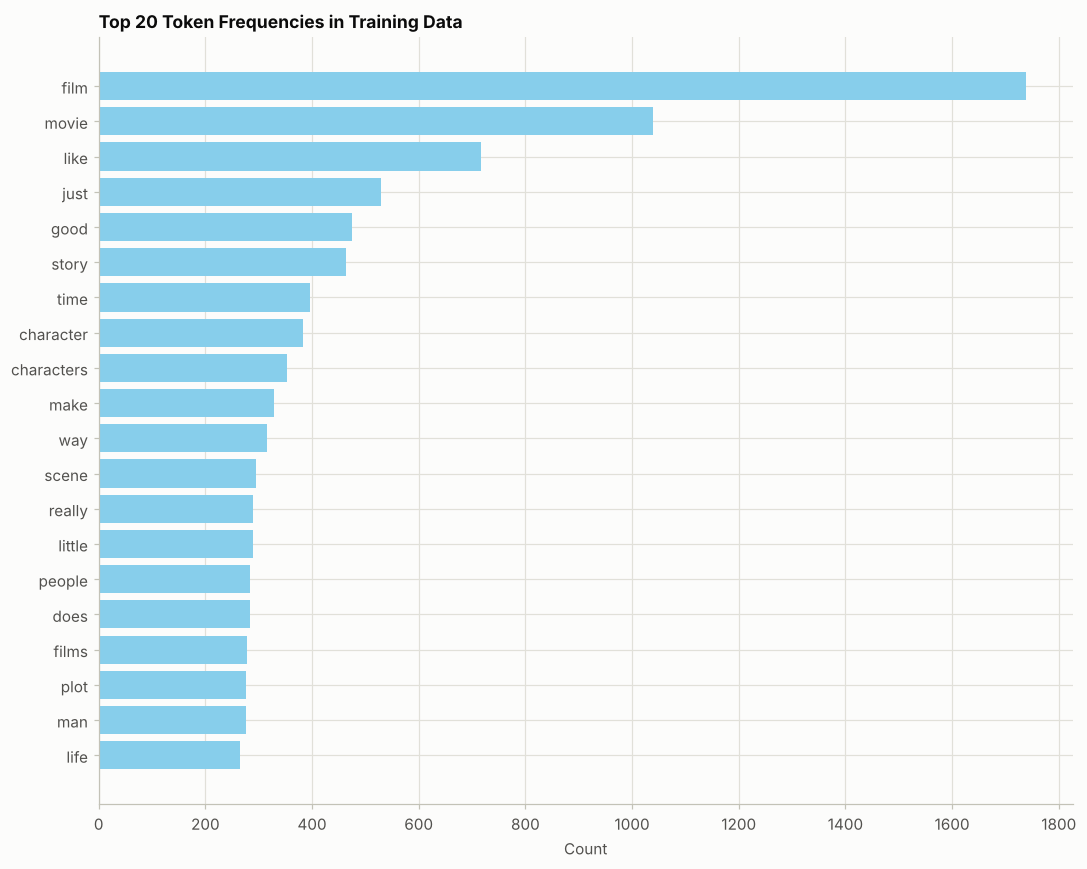

In [4]:
# BOOK CODE (pp. 216-217): visualizing the token counts (the official notebook plots the top 20 tokens)
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)

top_n = 20 # Display top N features
num_features = len(feature_names) # Should be equal to len(counts)

if num_features > 0:
    # Sort features by count
    # argsort sorts in ascending order, [::-1] reverses it for descending
    sorted_indices = np.argsort(counts)[::-1]

    actual_top_n = min(top_n, num_features)

    # Select top N features and their counts
    top_feature_names = feature_names[sorted_indices][:actual_top_n]
    top_counts = counts[sorted_indices][:actual_top_n]

    plt.figure(figsize=(10, 8)) # Adjusted figsize for better readability of N items
    plt.barh(top_feature_names, top_counts, color='skyblue')
    plt.xlabel('Count')
    plt.title(f'Top {actual_top_n} Token Frequencies in Training Data')

    # Dynamically set x-axis ticks using MaxNLocator for integer counts
    from matplotlib.ticker import MaxNLocator
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(left=0) # Ensure x-axis starts at 0

    ax.invert_yaxis() # Display the highest count at the top
    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()
else: # num_features == 0
    # Fallback for no features (e.g., if CountVectorizer found no words)
    plt.figure(figsize=(10,6)) # Use original figsize for this fallback
    plt.text(0.5, 0.5, 'No features to display.', ha='center', va='center')
    plt.title('Token Frequency in Training Data')
    plt.xticks([]) # No x-ticks
    plt.yticks([]) # No y-ticks
    plt.show()

In [5]:
# EXTRA: inspect what the book's code produced (the listings print nothing)
print(f"train matrix: {X_train_vect.shape[0]} reviews x {X_train_vect.shape[1]:,} tokens")
print(f"test matrix : {X_test_vect.shape[0]} reviews x {X_test_vect.shape[1]:,} tokens (same columns)")
print(f"class balance in the training texts: {np.bincount(y_train).tolist()} (neg, pos)")
print(f"first five columns of the vocabulary : {list(vectorizer.get_feature_names_out()[:5])}")
print(f"last five columns of the vocabulary  : {list(vectorizer.get_feature_names_out()[-5:])}")
print(f"most frequent tokens: {[(feature_names[i], int(counts[i])) for i in sorted_indices[:5]]}")

train matrix: 350 reviews x 18,881 tokens
test matrix : 150 reviews x 18,881 tokens (same columns)
class balance in the training texts: [175, 175] (neg, pos)
first five columns of the vocabulary : ['000', '05', '10', '100', '1000']
last five columns of the vocabulary  : ['zucker', 'zurg', 'zweibel', 'zwick', 'zwigoff']
most frequent tokens: [('film', 1739), ('movie', 1039), ('like', 717), ('just', 530), ('good', 475)]


**Output analysis.**

* The training matrix has **350 rows and 18,881 columns**, and the test matrix has the same 18,881 columns: the vocabulary comes from the training reviews alone. Stratification keeps the classes balanced (175 and 175).
* Columns are in **alphabetical order**: the vocabulary starts with numbers (`000`, `05`, `10`) and ends with `zwigoff`. Digits are tokens too.
* The most frequent token is `film` (1,739 occurrences), then `movie` (1,039), `like`, `just` and `good`. This confirms the book's remark that *film* and *movie* lead. They are also **domain stop words**: they appear in almost every review and say nothing about its sentiment. The list of English stop words cannot know that, and recipe 2's IDF weighting is the principled answer.
* The figure is the official notebook's version of the book's Figure 9.1, limited to the top 20 tokens. The book's printed listing passes *all* feature names to `barh`, which would draw 18,881 bars.

### Extra: experiments for recipe 1

**(a) The bag of words by hand.** A `CountVectorizer` is nothing more than a regular expression, a sorted vocabulary and a counter. The cell rebuilds it for three tiny documents and checks that the result is identical.

In [6]:
# EXTRA: (a) the bag of words by hand, checked against CountVectorizer
import re
from collections import Counter

toy = ["The film was good, the acting was good.",
       "A bad film: the plot was bad.",
       "Good film, bad ending!"]

token_pattern = re.compile(r"(?u)\b\w\w+\b")  # the default token_pattern of CountVectorizer
tokenized = [token_pattern.findall(doc.lower()) for doc in toy]
vocabulary = sorted({token for tokens in tokenized for token in tokens})
by_hand = np.array([[Counter(tokens)[term] for term in vocabulary] for tokens in tokenized])

toy_vectorizer = CountVectorizer()
toy_counts = toy_vectorizer.fit_transform(toy)
assert list(toy_vectorizer.get_feature_names_out()) == vocabulary
assert (toy_counts.toarray() == by_hand).all()
print("hand-made matrix equals CountVectorizer: True")
print("tokens of document 1:", tokenized[1], "  <- the one-letter word 'a' and the punctuation are gone")
pd.DataFrame(toy_counts.toarray(), columns=toy_vectorizer.get_feature_names_out(), index=[f"doc {i}" for i in range(len(toy))])

hand-made matrix equals CountVectorizer: True
tokens of document 1: ['bad', 'film', 'the', 'plot', 'was', 'bad']   <- the one-letter word 'a' and the punctuation are gone


,acting,bad,ending,film,good,plot,the,was
doc 0,1,0,0,1,2,0,2,2
doc 1,0,2,0,1,0,1,1,1
doc 2,0,1,1,1,1,0,0,0


**(b) Sparsity.** How much of the book's 350-review matrix is actually non-zero, and what would the dense version cost?

In [7]:
# EXTRA: (b) sparsity of the training matrix
n_docs, n_terms = X_train_vect.shape
nnz = X_train_vect.nnz
itemsize = X_train_vect.dtype.itemsize
dense_mb = n_docs * n_terms * itemsize / 1e6
csr_mb = (X_train_vect.data.nbytes + X_train_vect.indices.nbytes + X_train_vect.indptr.nbytes) / 1e6
distinct_per_review = np.diff(X_train_vect.indptr)

print(f"cells in the matrix            : {n_docs * n_terms:,}")
print(f"non-zero cells                 : {nnz:,} ({nnz / (n_docs * n_terms):.2%} of the cells)")
print(f"distinct tokens per review     : mean {distinct_per_review.mean():.0f}, min {distinct_per_review.min()}, max {distinct_per_review.max()}")
print(f"memory, dense int64 array      : {dense_mb:.1f} MB")
print(f"memory, sparse CSR matrix      : {csr_mb:.2f} MB ({dense_mb / csr_mb:.0f} times smaller)")
document_frequency = np.asarray((X_train_vect > 0).sum(axis=0)).ravel()
print(f"tokens found in a single review: {(document_frequency == 1).mean():.1%} of the vocabulary")

cells in the matrix            : 6,608,350
non-zero cells                 : 89,870 (1.36% of the cells)
distinct tokens per review     : mean 257, min 49, max 907
memory, dense int64 array      : 52.9 MB
memory, sparse CSR matrix      : 1.08 MB (49 times smaller)
tokens found in a single review: 49.7% of the vocabulary


**(c) Zipf's law.** The recipe's bar chart shows only the head of the distribution. The next figure ranks all tokens of the 2,000 reviews (no stop-word removal) by frequency, on logarithmic axes. A power law $f \propto r^{-s}$ is a straight line of slope $-s$.

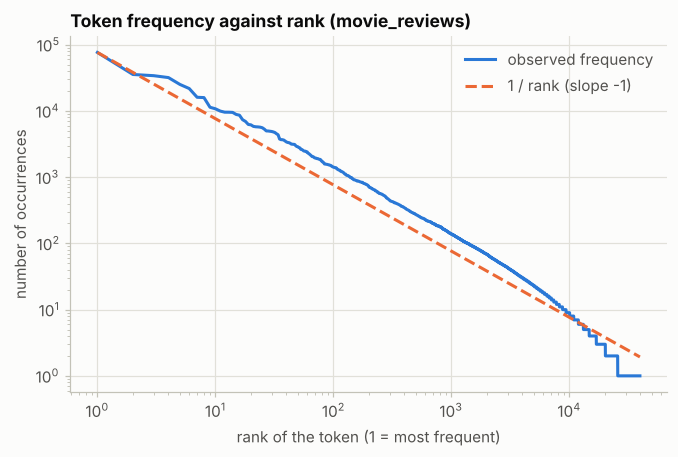

vocabulary size              : 39,659 distinct tokens, 1,259,869 token occurrences
fitted slope of the top 1000 : -0.98
share of all occurrences     : top 10 tokens 22.2%, top 100 46.3%, top 1000 71.9%
tokens that occur only once  : 13,982 (35.3% of the vocabulary)


In [8]:
# EXTRA: (c) Zipf's law on the whole corpus
full_counts = np.asarray(CountVectorizer().fit_transform(documents).sum(axis=0)).ravel()
frequency = np.sort(full_counts)[::-1]
rank = np.arange(1, len(frequency) + 1)
slope = np.polyfit(np.log(rank[:1000]), np.log(frequency[:1000]), 1)[0]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(rank, frequency, color=PALETTE[0], label="observed frequency")
ax.loglog(rank, frequency[0] / rank, color=PALETTE[1], linestyle="--", label="1 / rank (slope -1)")
ax.set_xlabel("rank of the token (1 = most frequent)")
ax.set_ylabel("number of occurrences")
ax.set_title("Token frequency against rank (movie_reviews)")
ax.legend()
plt.show()

total = frequency.sum()
print(f"vocabulary size              : {len(frequency):,} distinct tokens, {total:,} token occurrences")
print(f"fitted slope of the top 1000 : {slope:.2f}")
print(f"share of all occurrences     : top 10 tokens {frequency[:10].sum() / total:.1%}, top 100 {frequency[:100].sum() / total:.1%}, top 1000 {frequency[:1000].sum() / total:.1%}")
print(f"tokens that occur only once  : {(frequency == 1).sum():,} ({(frequency == 1).mean():.1%} of the vocabulary)")

**(d) What the stop-word list removes.** Without removal, the head of the distribution is made of function words. With the list, *film* and *movie* lead, as the book says. But the list also contains words that carry meaning:

In [9]:
# EXTRA: (d) the stop-word list: what it hides, what it removes
import warnings
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

plain = CountVectorizer().fit(X_train)
plain_counts = np.asarray(plain.transform(X_train).sum(axis=0)).ravel()
top_plain = [plain.get_feature_names_out()[i] for i in np.argsort(plain_counts)[::-1][:10]]
top_stop = [feature_names[i] for i in sorted_indices[:10]]
print(pd.DataFrame({"no stop-word removal": top_plain, "stop_words='english'": top_stop}, index=range(1, 11)).to_string())

print(f"\nwords in scikit-learn's English stop-word list: {len(ENGLISH_STOP_WORDS)}")
negations = [w for w in ["not", "no", "never", "nothing", "nobody", "none", "cannot", "neither", "nor"] if w in ENGLISH_STOP_WORDS]
intensifiers = [w for w in ["very", "too", "more", "most", "but", "however"] if w in ENGLISH_STOP_WORDS]
content = [w for w in ["system", "fire", "bill", "interest", "amount", "computer", "cry"] if w in ENGLISH_STOP_WORDS]
print("negations in the list     :", negations)
print("intensifiers and contrasts:", intensifiers)
print("content words in the list :", content)

# a custom list that does not match the tokenizer triggers a warning
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    CountVectorizer(stop_words=["don't", "i'm"]).fit(["I don't like it"])
print("\nwarning for a list that does not match the tokenizer:\n ", str(caught[0].message))

   no stop-word removal stop_words='english'
1                   the                 film
2                   and                movie
3                    of                 like
4                    to                 just
5                    is                 good
6                    in                story
7                  that                 time
8                    it            character
9                    as           characters
10                 with                 make

words in scikit-learn's English stop-word list: 318
negations in the list     : ['not', 'no', 'never', 'nothing', 'nobody', 'none', 'cannot', 'neither', 'nor']
intensifiers and contrasts: ['very', 'too', 'more', 'most', 'but', 'however']
content words in the list : ['system', 'fire', 'bill', 'interest', 'amount', 'cry']

warning for a list that does not match the tokenizer:
  Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['don'] not in stop_w

**(e) Words that the training set never saw.** `transform` ignores them. How much of the test text is lost?

In [10]:
# EXTRA: (e) out-of-vocabulary rate of the test texts (no stop-word removal)
analyzer = plain.build_analyzer()
test_tokens = [token for doc in X_test for token in analyzer(doc)]
vocab = plain.vocabulary_
oov_tokens = [token not in vocab for token in test_tokens]
test_types = set(test_tokens)
oov_types = {token for token in test_types if token not in vocab}

print(f"test tokens not in the training vocabulary: {np.mean(oov_tokens):.2%} of the {len(test_tokens):,} occurrences")
print(f"test token types not in the vocabulary    : {len(oov_types) / len(test_types):.1%} of the {len(test_types):,} distinct tokens")
print("examples of unseen tokens:", sorted(oov_types)[1000:1008])

test tokens not in the training vocabulary: 5.24% of the 96,364 occurrences
test token types not in the vocabulary    : 28.9% of the 12,202 distinct tokens
examples of unseen tokens: ['dunmore', 'duplicitous', 'durham', 'duties', 'dwarf', 'dwindling', 'dynamite', 'dynasty']


**(f) Which preprocessing options matter?** The book's pipeline fixes `stop_words='english'`. The cell below compares five settings on all 2,000 reviews with **repeated stratified 5-fold cross-validation** (two repeats, ten folds), a logistic regression on the counts, and the vectorizer *inside* the pipeline so that each fold learns its own vocabulary. All settings are scored on the **same ten folds**, so the last two columns compare each setting with the defaults fold by fold. Two details first: the `movie_reviews` corpus is **already lowercase**, so `lowercase=False` changes nothing; and the std column is the spread over the ten folds, not the error of the mean.

any uppercase letter in the 2,000 reviews: False


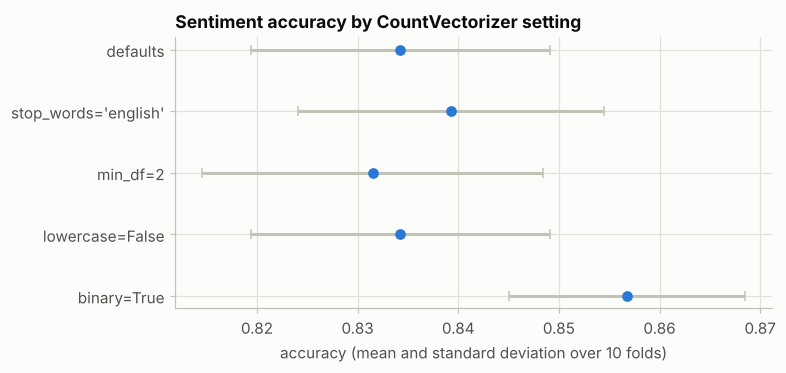

,mean accuracy,std over folds,mean gain over defaults,folds better than defaults
setting,,,,
defaults,0.8342,0.0149,0.0000,0
stop_words='english',0.8392,0.0152,0.0050,6
min_df=2,0.8315,0.0169,-0.0027,1
lowercase=False,0.8342,0.0149,0.0000,0
binary=True,0.8567,0.0117,0.0225,9


In [11]:
# EXTRA: (f) preprocessing choices compared by repeated cross-validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

print("any uppercase letter in the 2,000 reviews:", any(doc != doc.lower() for doc in documents))

settings = {
    "defaults": {},
    "stop_words='english'": {"stop_words": "english"},
    "min_df=2": {"min_df": 2},
    "lowercase=False": {"lowercase": False},
    "binary=True": {"binary": True},
}
cv_text = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
fold_scores = {}
for name, options in settings.items():
    pipeline = make_pipeline(CountVectorizer(**options), LogisticRegression(max_iter=1000))
    fold_scores[name] = cross_val_score(pipeline, documents, labels, cv=cv_text, n_jobs=-1)  # same 10 folds for every setting

baseline = fold_scores["defaults"]
preprocessing = pd.DataFrame({
    "mean accuracy": {name: s.mean() for name, s in fold_scores.items()},
    "std over folds": {name: s.std() for name, s in fold_scores.items()},
    "mean gain over defaults": {name: (s - baseline).mean() for name, s in fold_scores.items()},
    "folds better than defaults": {name: int((s > baseline).sum()) for name, s in fold_scores.items()},
})
preprocessing.index.name = "setting"

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(preprocessing["mean accuracy"], range(len(preprocessing)), xerr=preprocessing["std over folds"],
            fmt="o", color=PALETTE[0], ecolor=AXIS, capsize=3)
ax.set_yticks(range(len(preprocessing)))
ax.set_yticklabels(preprocessing.index)
ax.invert_yaxis()
ax.set_xlabel("accuracy (mean and standard deviation over 10 folds)")
ax.set_title("Sentiment accuracy by CountVectorizer setting")
plt.show()
preprocessing.round(4)

**Analysis of the extras.**

* **(a)** The hand-made matrix is identical to the library's. Note that the one-letter word *a* and all punctuation are gone, and that *the* is still there, since no stop-word list was given.
* **(b)** The training matrix is **1.36% filled**: a review uses 257 distinct tokens on average, out of 18,881. As a dense `int64` array it would take 52.9 MB; the CSR matrix takes 1.08 MB, 49 times less. Half of the vocabulary (49.7%) occurs in a **single** training review, and such columns cannot help a model generalize; `min_df=2` removes them.
* **(c)** Zipf's law holds: the slope fitted on the 1,000 most frequent tokens is **-0.98**, almost the -1 of the reference line. The 10 most frequent tokens make up 22.2% of all occurrences, the top 100 make up 46.3%, the top 1,000 make up 71.9%, while 35.3% of the vocabulary (13,982 tokens) occurs exactly once. The staircase at the end of the curve is that tail of tokens with counts 1, 2 and 3.
* **(d)** Without a list, the head of the distribution is made of function words (*the*, *and*, *of*, *to*). With `stop_words='english'`, *film* and *movie* lead. The list also removes words that matter for sentiment: **every negation tested** (*not*, *no*, *never*, *nothing*, *nobody*, *none*, *cannot*, *neither*, *nor*) and intensifiers such as *very* and *too*, so "not good" becomes "good" before counting. It contains content words as well (*system*, *fire*, *bill*, *interest*, *amount*, *cry*). A custom list whose entries do not match the tokenizer (*don't* is tokenized to *don*) triggers the warning shown.
* **(e)** 5.24% of the test token occurrences, and 28.9% of the distinct test tokens, are not in the training vocabulary and are dropped by `transform`. Most of them are rare names and words (*dunmore*, *dynasty*), which is expected from the long tail of Zipf's law.
* **(f)** On the same ten folds, `stop_words='english'` gains **0.5 percentage points** and wins on only 6 of the 10 folds, a gain smaller than the 1.5 points of spread between folds; `min_df=2` is not better than the defaults (1 fold of 10). `lowercase=False` is identical to the defaults because the corpus has no uppercase letter. The one setting that clearly matters is **`binary=True`** (presence instead of count), which gains **2.3 points** and beats the defaults on 9 of the 10 folds. For sentiment, whether a word occurs matters more than how often. The book's choice of stop-word removal is harmless here, not decisive.

---
## 2. Text vectorization techniques

### Summary

* **Vectorization** turns raw text into numbers. The book names three families: **Bag of Words (BoW)**, **TF-IDF** and **word embeddings**. Even before that, a computer must represent a letter, usually with ASCII or Unicode.
* **Getting ready** — the `reuters` corpus: 10,788 news documents, about 1.3 million words and "over 90 possible topics" (NLTK's copy has 90 categories). The book classifies "based on the first category for simplicity", and splits the documents 50/50 with `random_state=2024`.
* **How to do it** — `CountVectorizer()` gives BoW counts and `TfidfVectorizer()` gives TF-IDF weights, both fitted on the training half.
* **How it works** — BoW "represents texts as frequency counts of individual words, disregarding word order and grammar". TF-IDF "adjusts word frequencies by considering their rarity across all documents, assigning higher weights to distinctive terms" and "allows the classification of documents based on the occurrence of words much more efficiently". The book plots the 20 largest mean TF-IDF weights (Figure 9.2) and remarks that the tokens "look a bit odd" but are "highly valuable" for a classifier.
* **There's more** — **word embeddings** such as Word2Vec and GloVe represent words as dense vectors that capture semantic relations. Scikit-learn cannot train them, but embeddings built elsewhere can be fed to its models.
* **Hands-on exercises** — eight steps: vectorize with both techniques, split, train, evaluate, optionally use pretrained embeddings, and inspect the TF-IDF weights.

### Theory: TF-IDF, embeddings and the hashing trick

**TF-IDF.** The weight of term $t$ in document $d$ is the product of a **term frequency** and an **inverse document frequency**. With $n$ documents and $\text{df}(t)$ the number of documents that contain $t$, scikit-learn uses (with its default `smooth_idf=True`)

$$
\text{tf-idf}(t, d) = \text{tf}(t, d) \cdot \text{idf}(t), \qquad
\text{idf}(t) = \ln \frac{1 + n}{1 + \text{df}(t)} + 1 ,
$$

where $\text{tf}(t, d)$ is the raw count. Each row is then divided by its Euclidean length, $\mathbf{x}_d \leftarrow \mathbf{x}_d / \lVert \mathbf{x}_d \rVert_2$.

* **Why the IDF.** $\ln(n / \text{df})$ is the *information content* of "a random document contains $t$": a term found in every document says nothing, a term found in a handful of documents says a lot. IDF is a cheap, supervised-free estimate of how discriminative a term is (Spärck Jones, 1972).
* **The "+1".** Textbooks use $\ln(n/\text{df})$, which is 0 for a term present in every document. Scikit-learn adds 1, so such a term keeps a weight of 1 instead of vanishing; the smoothing adds one imaginary document containing every term, which avoids a division by zero.
* **The normalization.** After the L2 normalization, each document is a unit vector. The dot product of two documents is their **cosine similarity**, long and short documents are comparable, and the features of a linear model have a common scale.
* **Variants.** `sublinear_tf=True` replaces the count by $1 + \ln \text{tf}$, so that a word repeated 20 times is not 20 times as important. `use_idf=False` keeps only the normalized counts, and `norm='l1'` or `None` change the normalization. `TfidfVectorizer` is exactly `CountVectorizer` followed by `TfidfTransformer`.

**BoW or TF-IDF?** TF-IDF is not always better. Linear models such as SVMs and logistic regression profit from the reweighting and the normalization. **Naive Bayes** is a generative model of word *counts*; fed with TF-IDF it still runs, but its smoothing parameter must be retuned (recipe 4 shows why). The extra experiment below puts numbers on the book's claim.

**Word embeddings.** BoW and TF-IDF are **sparse, high-dimensional** and treat *wheat* and *corn* as unrelated columns. Embeddings are **dense, low-dimensional** (typically 50 to 300 numbers) vectors in which related words are close, following the *distributional hypothesis*: words that occur in similar contexts have similar meanings. Three classical constructions:

* **Latent semantic analysis (LSA)** — a truncated singular value decomposition of the term-document matrix, $X \approx U_k \Sigma_k V_k^\top$ (Deerwester et al., 1990). The rows of $U_k \Sigma_k$ are document vectors and the rows of $V_k$ are term vectors. Scikit-learn offers it as `TruncatedSVD`, and the extra below uses it.
* **Word2Vec** (Mikolov et al., 2013) — a shallow network trained to predict context words. Its skip-gram objective with negative sampling maximizes, over observed pairs $(w, c)$ and $k$ random "negative" words $n$,
  $\log \sigma(\mathbf{v}_w \cdot \mathbf{u}_c) + \sum_{i=1}^{k} \log \sigma(-\mathbf{v}_w \cdot \mathbf{u}_{n_i})$.
  It implicitly factorizes a shifted pointwise-mutual-information matrix (Levy & Goldberg, 2014).
* **GloVe** (Pennington et al., 2014) — a weighted least-squares fit of word vectors to the logarithm of the co-occurrence counts $X_{ij}$: $\sum_{i,j} f(X_{ij}) (\mathbf{w}_i^\top \tilde{\mathbf{w}}_j + b_i + \tilde b_j - \ln X_{ij})^2$.

Scikit-learn does not train Word2Vec or GloVe. A document is usually represented by the average of its word vectors, and the resulting dense matrix goes to any estimator. Modern large language models start from the same idea with *contextual* embeddings, computed outside scikit-learn.

**The hashing trick.** `CountVectorizer` must store a vocabulary, which costs memory and prevents parallel or streaming use. `HashingVectorizer` skips it: the column of a token is `hash(token) mod m`, for a fixed number of columns $m$ (Weinberger et al., 2009). It is stateless, but different tokens can **collide** in one column, and the original tokens cannot be recovered from the columns. By default scikit-learn gives each token a random sign (`alternate_sign=True`) so that collisions cancel on average.

### Book code (pp. 218–222)

The corpus is `reuters`. The label of each document is its **first** category (a document can have several).

In [12]:
# BOOK CODE (pp. 218-219): load the libraries, load the reuters corpus, split the data
# Load the libraries
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import reuters
import matplotlib.pyplot as plt

# Download the Reuters corpus if not already downloaded
try:
    reuters.fileids()
except LookupError:
    nltk.download('reuters')

# Load the dataset from NLTK Reuters corpus
documents = reuters.fileids()
texts = [reuters.raw(doc_id) for doc_id in documents]

labels = [reuters.categories(doc_id)[0] for doc_id in documents] # Using the first category as the label for simplicity

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

In [13]:
# BOOK CODE (p. 219): Bag of Words and TF-IDF vectorization
# Bag of Words (BoW)
# Instantiate and fit CountVectorizer()
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF Vectorization
# Instantiate and fit TfidfVectorizer()
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

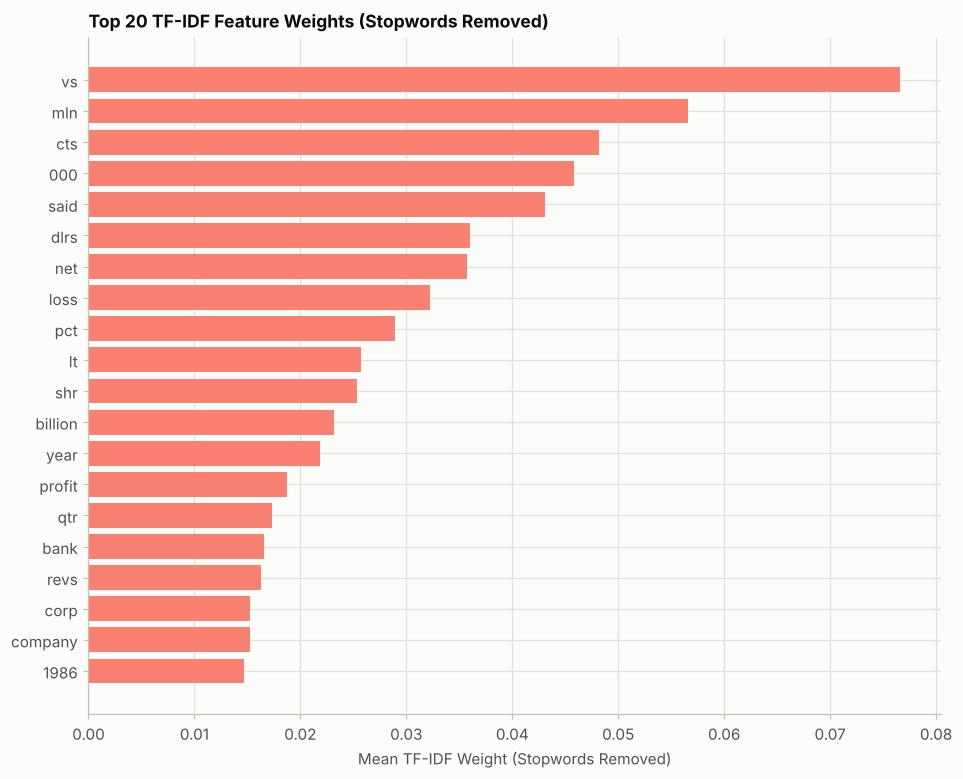

In [14]:
# BOOK CODE (pp. 220-222): visualizing the top 20 TF-IDF feature weights
# Create a TfidfVectorizer instance with English stop words removed
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = vis_tfidf_vectorizer.fit_transform(X_train)

# Get feature names and their mean TF-IDF weights from this new vectorization
feature_names = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = vis_X_train_tfidf.toarray().mean(axis=0)

# Number of top terms to display
N = 20

# Ensure N is not greater than the number of available features
if len(feature_names) < N:
    N = len(feature_names)

# Get indices of the N largest TF-IDF means.
# np.argsort sorts in ascending order, so we take the last N indices.
# These indices will correspond to the N features with the highest TF-IDF scores,
# sorted from the Nth highest to the 1st highest (suitable for plt.barh to plot highest at top).
if N > 0 : # Proceed only if there are features to plot
    sorted_indices_ascending = np.argsort(tfidf_means)
    top_n_plotting_indices = sorted_indices_ascending[-N:]

    # Select the top N feature names and their TF-IDF means using these indices
    plot_feature_names = feature_names[top_n_plotting_indices]
    plot_tfidf_means = tfidf_means[top_n_plotting_indices]

    # Create the plot
    plt.figure(figsize=(10, 8)) # Adjusted figsize for better readability with 20 items
    plt.barh(plot_feature_names, plot_tfidf_means, color='salmon')
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title(f'Top {N} TF-IDF Feature Weights (Stopwords Removed)')
else: # Handle case with no features (e.g., if all features were stopwords or N=0)
    plt.figure(figsize=(10, 6)) # Original figsize for empty or minimal plot
    plt.barh([], []) # Plot empty data
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title('TF-IDF Feature Weights (No non-stopword features to display)')

plt.show()

In [15]:
# EXTRA: inspect what the book's code produced
print(f"documents: {len(documents):,} in total, {len(X_train):,} for training and {len(X_test):,} for testing")
print(f"BoW matrix   : {X_train_bow.shape[0]:,} x {X_train_bow.shape[1]:,}, {X_train_bow.nnz:,} non-zero cells ({X_train_bow.nnz / np.prod(X_train_bow.shape):.2%})")
print(f"TF-IDF matrix: {X_train_tfidf.shape[0]:,} x {X_train_tfidf.shape[1]:,}, same sparsity pattern: {(X_train_bow != 0).nnz == (X_train_tfidf != 0).nnz}")
print(f"same vocabulary in both vectorizers: {bow_vectorizer.vocabulary_ == tfidf_vectorizer.vocabulary_}")
print(f"squared length of the first three TF-IDF rows: {[round(float(r.multiply(r).sum()), 6) for r in X_train_tfidf[:3]]}")
print(f"largest mean TF-IDF weights: {[(feature_names[i], round(float(tfidf_means[i]), 4)) for i in sorted_indices_ascending[::-1][:5]]}")

multi = [len(reuters.categories(doc_id)) for doc_id in documents]
distinct_first = len(set(labels))
print(f"\ndocuments with more than one category: {sum(m > 1 for m in multi):,} of {len(multi):,}")
print(f"categories in the corpus: {len(reuters.categories())}, distinct first categories used as labels: {distinct_first}")
print("first category is the alphabetically first one:",
      all(reuters.categories(d)[0] == sorted(reuters.categories(d))[0] for d in documents))
unseen = set(y_test) - set(y_train)
print(f"categories used as labels in the training half: {len(set(y_train))}")
print(f"test documents whose label never occurs in the training half: {sum(label in unseen for label in y_test)} (from {len(unseen)} categories)")

documents: 10,788 in total, 5,394 for training and 5,394 for testing
BoW matrix   : 5,394 x 22,864, 392,516 non-zero cells (0.32%)
TF-IDF matrix: 5,394 x 22,864, same sparsity pattern: True
same vocabulary in both vectorizers: True
squared length of the first three TF-IDF rows: [1.0, 1.0, 1.0]
largest mean TF-IDF weights: [('vs', 0.0766), ('mln', 0.0565), ('cts', 0.0482), ('000', 0.0459), ('said', 0.0431)]

documents with more than one category: 1,628 of 10,788
categories in the corpus: 90, distinct first categories used as labels: 79
first category is the alphabetically first one: True
categories used as labels in the training half: 74
test documents whose label never occurs in the training half: 10 (from 5 categories)


**Output analysis.**

* The 10,788 documents are split into 5,394 for training and 5,394 for testing. `CountVectorizer` and `TfidfVectorizer` learn the **same vocabulary** of 22,864 tokens and the **same sparsity pattern** (0.32% of the cells are non-zero): TF-IDF changes the values of the non-zero cells, not which cells are non-zero. Every TF-IDF row has squared length 1, the L2 normalization of the theory.
* The largest mean weights are `vs` (0.0766), `mln`, `cts`, `000` and `said`, as in the book's Figure 9.2. The book is right that they "look a bit odd"; extra (b) explains them.
* **The label is less clean than it looks.** 1,628 of the 10,788 documents (15%) carry more than one category, and the "first category" is simply the alphabetically first one, not the main topic. Of the 90 categories, 79 occur as a first category, and 10 test documents belong to 5 categories that never appear in the training half, so no model can predict them.

### Extra: experiments for recipe 2

**(a) TF-IDF by hand.** The formula above, applied to five tiny documents, reproduces `TfidfVectorizer` exactly. The figure then shows how the three IDF conventions behave on the real Reuters training half.

hand-made idf and TF-IDF equal TfidfVectorizer: True

        df    idf
acting   1  2.099
bad      2  1.693
film     3  1.405
good     2  1.693
great    1  2.099
had      1  2.099
plot     2  1.693
the      5  1.000
was      4  1.182

TF-IDF of document 0, 'the film was good':
film    0.522
good    0.629
the     0.372
was     0.439


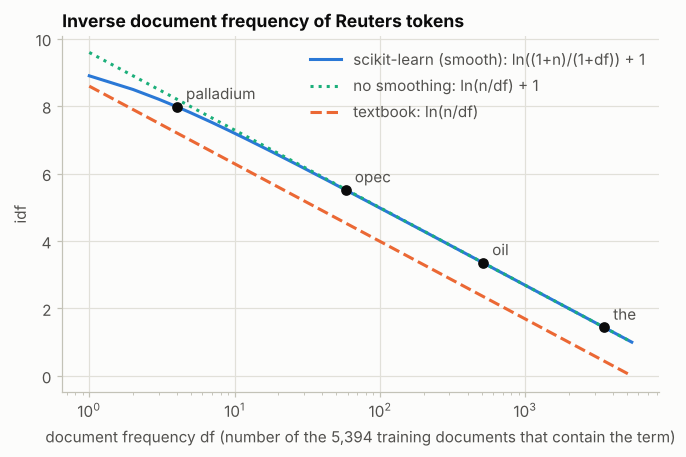

{'the': 'df 3,476, idf 1.44', 'oil': 'df 511, idf 3.35', 'opec': 'df 58, idf 5.52', 'palladium': 'df 4, idf 7.98'}


In [16]:
# EXTRA: (a) TF-IDF by hand, checked against TfidfVectorizer
toy = ["the film was good",
       "the film was bad",
       "the acting was good",
       "the plot was bad",
       "the film had a great plot"]
toy_bow = CountVectorizer().fit(toy)
counts = toy_bow.transform(toy).toarray().astype(float)
n_toy = counts.shape[0]
df_toy = (counts > 0).sum(axis=0)
idf_toy = np.log((1 + n_toy) / (1 + df_toy)) + 1          # smooth_idf=True
weights = counts * idf_toy
by_hand = weights / np.linalg.norm(weights, axis=1, keepdims=True)   # L2 normalization of each row

toy_tfidf = TfidfVectorizer().fit(toy)
assert np.allclose(idf_toy, toy_tfidf.idf_)
assert np.allclose(by_hand, toy_tfidf.transform(toy).toarray())
print("hand-made idf and TF-IDF equal TfidfVectorizer: True\n")
print(pd.DataFrame({"df": df_toy, "idf": idf_toy.round(3)}, index=toy_bow.get_feature_names_out()).to_string())
print("\nTF-IDF of document 0, 'the film was good':")
print(pd.Series(by_hand[0], index=toy_bow.get_feature_names_out()).round(3)[lambda s: s > 0].to_string())

# the three IDF conventions on the Reuters training half
n_docs_r = X_train_bow.shape[0]
df_r = np.asarray((X_train_bow > 0).sum(axis=0)).ravel()
df_grid = np.arange(1, n_docs_r + 1)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(df_grid, np.log((1 + n_docs_r) / (1 + df_grid)) + 1, color=PALETTE[0], label="scikit-learn (smooth): ln((1+n)/(1+df)) + 1")
ax.plot(df_grid, np.log(n_docs_r / df_grid) + 1, color=PALETTE[2], linestyle=":", label="no smoothing: ln(n/df) + 1")
ax.plot(df_grid, np.log(n_docs_r / df_grid), color=PALETTE[1], linestyle="--", label="textbook: ln(n/df)")
for word in ["the", "oil", "opec", "palladium"]:
    j = bow_vectorizer.vocabulary_[word]
    ax.plot(df_r[j], tfidf_vectorizer.idf_[j], "o", color=INK)
    ax.annotate(word, (df_r[j], tfidf_vectorizer.idf_[j]), textcoords="offset points", xytext=(6, 5), color=INK_SOFT)
ax.set_xscale("log")
ax.set_xlabel(f"document frequency df (number of the {n_docs_r:,} training documents that contain the term)")
ax.set_ylabel("idf")
ax.set_title("Inverse document frequency of Reuters tokens")
ax.legend(loc="upper right")
plt.show()
print({word: f"df {int(df_r[bow_vectorizer.vocabulary_[word]]):,}, idf {tfidf_vectorizer.idf_[bow_vectorizer.vocabulary_[word]]:.2f}" for word in ["the", "oil", "opec", "palladium"]})

**(b) What are the "top 20 TF-IDF weights"?** The book averages each column of the TF-IDF matrix over all documents. That mean is the *sum* of a term's weights divided by $n$, so it is large for a term that is **frequent across many documents**. The table lists the largest means with the share of documents that contain each term.

In [17]:
# EXTRA: (b) the largest mean TF-IDF weights and how common those terms are
from scipy.stats import spearmanr

doc_share = np.asarray((vis_X_train_tfidf > 0).mean(axis=0)).ravel()
order = np.argsort(tfidf_means)[::-1][:15]
top_table = pd.DataFrame({
    "mean TF-IDF": tfidf_means[order].round(4),
    "share of documents containing it": doc_share[order].round(3),
    "mean weight where present": (tfidf_means[order] / doc_share[order]).round(3),
}, index=feature_names[order])
print(top_table.to_string())
rho = spearmanr(tfidf_means, doc_share)[0]
print(f"\nSpearman correlation between mean TF-IDF and the share of documents, over all {len(feature_names):,} terms: {rho:.2f}")
share_lt = np.mean(["&lt;" in text for text in X_train])
print(f"training documents whose raw text contains the markup '&lt;': {share_lt:.1%}")
print("an excerpt:", " ".join(next(t for t in X_train if "&lt;" in t).split())[:150])

         mean TF-IDF  share of documents containing it  mean weight where present
vs            0.0766                             0.279                      0.275
mln           0.0565                             0.450                      0.126
cts           0.0482                             0.286                      0.168
000           0.0459                             0.281                      0.163
said          0.0431                             0.630                      0.068
dlrs          0.0360                             0.392                      0.092
net           0.0357                             0.269                      0.133
loss          0.0323                             0.130                      0.249
pct           0.0290                             0.303                      0.096
lt            0.0258                             0.557                      0.046
shr           0.0253                             0.222                      0.114
billion       0.

The strange tokens are abbreviations of **Reuters financial wires**: `vs` (versus, as in "profit 2.1 mln vs 1.8 mln"), `mln` (million), `cts` (cents), `dlrs` (dollars), `pct` (percent), `shr` (shares), `qtr` (quarter), `revs` (revenues) and `lt`. The last one is an artifact: company tickers are written `<ABC>` in the wire, and the corpus stores the angle brackets as the HTML entities `&lt;` and `&gt;`, so the tokenizer reads `lt` as a word. These are useful features for telling earnings reports apart from other news, but they are not "distinctive terms" of the corpus as a whole.

**(c) What the weights say about a category.** The mean over *all* documents mixes the topics. Subtracting the overall mean from the mean of one category shows the terms that characterize that category.

In [18]:
# EXTRA: (c) terms with the largest mean TF-IDF gain inside four categories
y_arr = np.array(y_train)
overall = np.asarray(vis_X_train_tfidf.mean(axis=0)).ravel()
columns = {}
for category in ["earn", "grain", "crude", "trade"]:
    in_class = np.asarray(vis_X_train_tfidf[y_arr == category].mean(axis=0)).ravel()
    best = np.argsort(in_class - overall)[::-1][:8]
    columns[f"{category} ({(y_arr == category).sum()} docs)"] = list(feature_names[best])
print(pd.DataFrame(columns, index=range(1, 9)).to_string())

  earn (1972 docs) grain (131 docs) crude (256 docs) trade (172 docs)
1               vs            wheat              oil            trade
2              cts           tonnes            crude            japan
3              net            grain             opec         japanese
4              000             usda              bpd          surplus
5             loss             crop           barrel          billion
6              mln      agriculture          barrels          deficit
7              shr             rice           prices          exports
8           profit       department              bbl          tariffs


**(d) Does TF-IDF help a classifier?** The book says TF-IDF allows classification "much more efficiently". The experiment fits the same two models on four weightings of the book's training half and scores them on the book's test half, with the labels of the book (first category, 74 classes in the training half): a **linear SVM** and **multinomial Naive Bayes**, whose smoothing `alpha` is chosen by 3-fold cross-validation on the training half. Accuracy is dominated by the two large classes (*earn* and *acq*), so the table also reports the **macro F1**, the unweighted mean over the categories.

In [19]:
# EXTRA: (d) BoW versus TF-IDF for a linear SVM and for Naive Bayes
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

weightings = {
    "counts (BoW)": CountVectorizer(),
    "binary presence": CountVectorizer(binary=True),
    "TF-IDF": TfidfVectorizer(),
    "TF-IDF, sublinear tf": TfidfVectorizer(sublinear_tf=True),
}
alphas = [1, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]
rows, not_converged = [], []
for name, vec in weightings.items():
    A = vec.fit_transform(X_train)
    B = vec.transform(X_test)
    with warnings.catch_warnings(record=True) as caught:  # liblinear is slow to converge on unscaled counts
        warnings.simplefilter("always")
        svm = LinearSVC(random_state=2024).fit(A, y_train)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        not_converged.append(name)
    search = GridSearchCV(MultinomialNB(), {"alpha": alphas}, cv=KFold(3, shuffle=True, random_state=2024)).fit(A, y_train)
    for model_name, model in [("LinearSVC", svm), (f"MultinomialNB (alpha={search.best_params_['alpha']})", search.best_estimator_)]:
        predicted = model.predict(B)
        rows.append({"features": name, "model": model_name,
                     "accuracy": accuracy_score(y_test, predicted),
                     "macro F1": f1_score(y_test, predicted, average="macro", zero_division=0)})
comparison = pd.DataFrame(rows)
baseline = max(np.unique(y_test, return_counts=True)[1]) / len(y_test)
print(f"majority-class accuracy: {baseline:.3f}")
print(f"LinearSVC reached its 1,000-iteration limit (ConvergenceWarning, silenced above) on: {not_converged}\n")
comparison.round(3)

majority-class accuracy: 0.362
LinearSVC reached its 1,000-iteration limit (ConvergenceWarning, silenced above) on: ['counts (BoW)', 'binary presence']



,features,model,accuracy,macro F1
0,counts (BoW),LinearSVC,0.883,0.549
1,counts (BoW),MultinomialNB (alpha=0.03),0.832,0.459
2,binary presence,LinearSVC,0.870,0.516
3,binary presence,MultinomialNB (alpha=0.03),0.813,0.419
4,TF-IDF,LinearSVC,0.903,0.608
5,TF-IDF,MultinomialNB (alpha=0.003),0.829,0.455
6,"TF-IDF, sublinear tf",LinearSVC,0.906,0.606
7,"TF-IDF, sublinear tf",MultinomialNB (alpha=0.003),0.821,0.453


**(e) Dense vectors from sparse ones: LSA.** A truncated SVD of the TF-IDF matrix keeps the $k$ directions of largest variance. The figure scores a linear SVM on the $k$-dimensional document vectors against the full 22,864-column TF-IDF matrix; the table lists the nearest terms of three words in the 100-dimensional term space (cosine similarity).

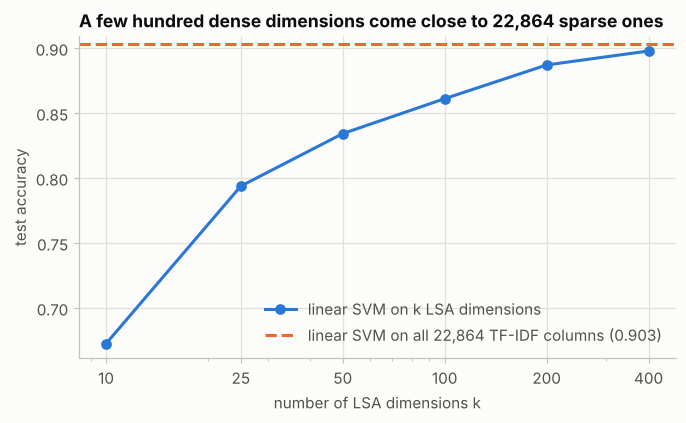

{10: 0.673, 25: 0.794, 50: 0.834, 100: 0.861, 200: 0.887, 400: 0.898}
           oil       wheat       dollar
1   recovering      winter      decline
2   dependence         red        slide
3        wells      poland  intervening
4      alaskan        soft      rebound
5     windfall  subsidized  speculative
6      chevron      arrive       finish
7         spur  yugoslavia      bearish
8  exploratory        hard    desperate


In [20]:
# EXTRA: (e) latent semantic analysis with TruncatedSVD
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

full_accuracy = accuracy_score(y_test, LinearSVC(random_state=2024).fit(X_train_tfidf, y_train).predict(X_test_tfidf))
ks = [10, 25, 50, 100, 200, 400]
lsa_accuracy = []
for k in ks:
    svd = TruncatedSVD(n_components=k, random_state=2024)
    normalizer = Normalizer()
    Z_train = normalizer.fit_transform(svd.fit_transform(X_train_tfidf))
    Z_test = normalizer.transform(svd.transform(X_test_tfidf))
    lsa_accuracy.append(accuracy_score(y_test, LinearSVC(random_state=2024).fit(Z_train, y_train).predict(Z_test)))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ks, lsa_accuracy, "o-", color=PALETTE[0], label="linear SVM on k LSA dimensions")
ax.axhline(full_accuracy, color=PALETTE[1], linestyle="--", label=f"linear SVM on all {X_train_tfidf.shape[1]:,} TF-IDF columns ({full_accuracy:.3f})")
ax.set_xscale("log")
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("number of LSA dimensions k")
ax.set_ylabel("test accuracy")
ax.set_title("A few hundred dense dimensions come close to 22,864 sparse ones")
ax.legend(loc="lower right")
plt.show()
print({k: round(a, 3) for k, a in zip(ks, lsa_accuracy)})

# nearest terms in the 100-dimensional LSA space (stop words removed, terms seen in at least 5 documents)
term_vectorizer = TfidfVectorizer(stop_words="english", min_df=5)
term_matrix = term_vectorizer.fit_transform(X_train)
term_svd = TruncatedSVD(n_components=100, random_state=2024).fit(term_matrix)
term_vectors = term_svd.components_.T
term_vectors = term_vectors / np.linalg.norm(term_vectors, axis=1, keepdims=True)
vocab_names = term_vectorizer.get_feature_names_out()
neighbours = {}
for word in ["oil", "wheat", "dollar"]:
    sims = term_vectors @ term_vectors[term_vectorizer.vocabulary_[word]]
    neighbours[word] = list(vocab_names[np.argsort(sims)[::-1][1:9]])
print(pd.DataFrame(neighbours, index=range(1, 9)).to_string())

**(f) The hashing trick.** `HashingVectorizer` needs no vocabulary, at the price of collisions. How many of the 22,864 training tokens share a column with another token, as a function of the number of columns $m = 2^b$? And does the classifier notice?

In [21]:
# EXTRA: (f) collisions of the hashing trick and their effect on accuracy
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer

terms = list(bow_vectorizer.vocabulary_)
rows = []
for bits in [12, 14, 16, 18, 20]:
    hasher = HashingVectorizer(n_features=2**bits, alternate_sign=False, norm=None)
    buckets = hasher.transform(terms).indices          # each term is a one-token document
    rows.append({"columns": f"2^{bits} = {2**bits:,}",
                 "tokens in a shared column": len(terms) - len(set(buckets)),
                 "share of the vocabulary": (len(terms) - len(set(buckets))) / len(terms)})
print(pd.DataFrame(rows).set_index("columns").round(3).to_string())

scores = {}
for bits in [12, 14, 18]:
    hasher = HashingVectorizer(n_features=2**bits, alternate_sign=False, norm=None)
    weigher = TfidfTransformer()
    H_train = weigher.fit_transform(hasher.transform(X_train))
    H_test = weigher.transform(hasher.transform(X_test))
    scores[f"2^{bits}"] = accuracy_score(y_test, LinearSVC(random_state=2024).fit(H_train, y_train).predict(H_test))
print("\ntest accuracy of a linear SVM on hashed TF-IDF features:", {k: round(v, 3) for k, v in scores.items()})
print(f"with the exact vocabulary ({len(terms):,} columns): {full_accuracy:.3f}")

                  tokens in a shared column  share of the vocabulary
columns                                                             
2^12 = 4,096                          18782                    0.821
2^14 = 16,384                         10481                    0.458
2^16 = 65,536                          3524                    0.154
2^18 = 262,144                          954                    0.042
2^20 = 1,048,576                        274                    0.012

test accuracy of a linear SVM on hashed TF-IDF features: {'2^12': 0.898, '2^14': 0.902, '2^18': 0.902}
with the exact vocabulary (22,864 columns): 0.903


**Analysis of the extras.**

* **(a)** The hand-made IDF and TF-IDF equal the library's. *the* occurs in all five toy documents, so its IDF is exactly 1 (the "+1" of scikit-learn: $\ln(6/6) + 1$), while terms found in a single document get $\ln(6/2) + 1 = 2.099$. In document 0, *good* (document frequency 2) outweighs *the* (document frequency 5), although both occur once. In the figure, the three conventions differ by a constant shift of 1 (smooth and unsmoothed against the textbook formula), except for terms with a very small document frequency, where the smoothing pulls the value down. The marked words show the logarithmic scale: *the* (in 3,476 of the 5,394 documents) has an IDF of 1.44, *oil* (511 documents) 3.35, *opec* (58) 5.52 and *palladium* (4) 7.98; the IDF falls by about $\ln 10 \approx 2.3$ for every tenfold increase of the document frequency.
* **(b)** The mean TF-IDF mostly measures how **widespread** a term is: its Spearman correlation with the share of documents containing the term is 0.84 over the whole vocabulary. `vs` appears in only 27.9% of the documents but with a high weight where present (0.275), because it is common inside earnings reports; `said` is in 63.0% of the documents with a low weight (0.068), because its IDF is low. 55.7% of the training documents contain the `&lt;` markup, which explains `lt`.
* **(c)** Inside a category, the largest gains are the words one would expect: *earn* has `vs`, `cts`, `net`, `loss`, `shr`, `profit`; *grain* has `wheat`, `tonnes`, `usda`, `crop`; *crude* has `oil`, `opec`, `bpd`, `barrel`; *trade* has `japan`, `surplus`, `deficit`, `tariffs`. The overall top 20 is dominated by earnings shorthand because 1,972 of the 5,394 training documents (37%) belong to *earn*.
* **(d)** For the **linear SVM**, TF-IDF beats raw counts by 2.0 points of accuracy (0.903 against 0.883) and by 5.9 points of macro F1 (0.608 against 0.549); the gain is concentrated in the small categories. Sublinear tf is a wash (0.906 and 0.606). Binary presence is worse here (0.870), the opposite of the sentiment task of recipe 1. For **Naive Bayes** the weighting does not help: after retuning `alpha` (0.03 for counts, 0.003 for TF-IDF) the accuracies are 0.832 and 0.829. So the book's claim holds for a linear model, not for Naive Bayes, and "efficiently" is about accuracy, not about speed. All models are far above the 0.362 of the majority class, and the macro F1 is much lower than the accuracy because of the many tiny classes. Liblinear hit its iteration limit on the unscaled count features (two of the four feature sets), another practical advantage of the normalized TF-IDF rows.
* **(e)** LSA compresses 22,864 columns into a few hundred dense dimensions: 25 dimensions give 0.794, 100 give 0.861 and **400 give 0.898**, about half a point below the full 0.903. In the 100-dimensional space, the neighbours of *wheat* include *winter*, *red*, *soft* and *hard* (kinds of wheat), those of *dollar* include *decline*, *slide*, *rebound* and *bearish*, and those of *oil* include *wells*, *Alaskan*, *Chevron* and *exploratory*. The neighbours also contain noise (*finish*, *desperate*, *spur*): 100 linear dimensions are a crude version of what Word2Vec or GloVe learn from far larger corpora.
* **(f)** With 4,096 columns, 82% of the 22,864 tokens share a column with another token, and yet the linear SVM scores 0.898, against 0.903 with the exact vocabulary; with $2^{14}$ and $2^{18}$ columns it scores 0.902. Colliding tokens are mostly rare ones, and the discriminative words are few. The price of hashing is not accuracy but interpretability: a column cannot be mapped back to a token.

---
## 3. Feature extraction from text

### Summary

* Feature extraction identifies "meaningful patterns and attributes within textual data". The book names three techniques, **n-grams**, **part-of-speech (POS) tagging** and **named entity recognition (NER)**, and says they improve "model accuracy and interpretability".
* **Getting ready** — the `brown` corpus: 500 documents "categorized by genre". The recipe takes the first two categories (`adventure` and `belles_lettres`), the first **two sentences** of each, so four sentences in total, and splits them 50/50 with `random_state=2024`: two sentences for training, two for testing.
* **How to do it** — (1) `CountVectorizer(ngram_range=(1, 2))` extracts unigrams and bigrams; (2) NLTK's `pos_tag` tags the tokens of each training sentence; (3) the listing prints the tagged tokens and the tagged bigrams. The book lists the tags that appear (`NN`, `NNS`, `JJ`, `VB`, `RB`, `PRP`, `CC`, `DT`, `IN`, `CD`, `FW`, `NNP`, `NNPS`, `VBZ`, `VBD`, `VBG`, `VBN`, `VBP`) and warns that "different taggers sometimes assign different tag labels".
* **How it works** — n-grams capture word sequences and overlap; POS tagging assigns grammatical types; "NER identifies and classifies named entities such as persons, organizations, and locations". The book visualizes the ten most frequent POS tags after stop-word removal (Figure 9.3) and expects "proper nouns, nouns, and adjectives" to dominate.
* **There's more** — dependency parsing and sentiment analysis. The hands-on exercises add **spaCy** for POS tagging and NER.
* **A gap in the listing:** the text says the recipe extracts "three elements", but the code has no NER step. The notebook adds one with NLTK's chunker in extra (e).

### Theory: n-grams, tags and entities

**N-grams.** An **n-gram** is a sequence of $n$ consecutive tokens. A document of $T$ tokens has $T - n + 1$ of them, and they **overlap**: in "Dan Morgan told himself", the bigrams are *dan morgan*, *morgan told* and *told himself*. With `ngram_range=(1, 2)`, `CountVectorizer` adds every bigram to the unigram vocabulary. N-grams are a cheap way to give a bag-of-words model a little **context**: *not good* is a different feature from *not* and *good*, and *new york* from *new* and *york*. The cost is **sparsity**. There are up to $|V|^n$ possible n-grams, the number actually seen grows with the corpus, and most of them occur once, so `min_df` is the usual companion of `ngram_range`. N-grams of characters (`analyzer='char_wb'`) are the same idea at the level of letters, and are robust to misspellings. The probabilistic view is the **n-gram language model**, which approximates $P(w_t \mid w_1, \dots, w_{t-1})$ by $P(w_t \mid w_{t-n+1}, \dots, w_{t-1})$ (a Markov assumption).

**Part-of-speech tagging** labels every token with its grammatical category. It is a **sequence-labelling** problem: *plot* is a noun in "the plot thickens" and a verb in "they plot a route", and only the context decides. NLTK's default tagger is an **averaged perceptron** (a linear model whose weights are averaged over the training run) that tags greedily from left to right, using as features the word itself, its prefix and suffix, the neighbouring words and the two previous tags. It outputs the **Penn Treebank** tags: 36 word tags (`NN` singular noun, `NNS` plural noun, `NNP` proper noun, `JJ` adjective, `RB` adverb, `VB*` verb forms, `DT` determiner, `IN` preposition, `CC` conjunction, `PRP` pronoun, `MD` modal, `CD` number, and so on) plus punctuation tags. POS information enters a classifier as **counts or proportions of tags** (a style signal that does not depend on the topic), as **tag n-grams** (*DT JJ NN* is a noun phrase), or as a **filter** (keep only nouns and adjectives).

**Named entity recognition** finds the spans of text that name things and classifies them (`PERSON`, `ORGANIZATION`, `GPE` for countries and cities, `LOCATION`, dates, amounts). It is again a sequence-labelling problem, usually written with the **BIO scheme**: `B-PER` begins a person, `I-PER` continues it, `O` is outside any entity. NLTK's `ne_chunk` is a maximum-entropy classifier over POS-tagged tokens; spaCy ships statistical pipelines that do POS tagging, parsing and NER together. Entities become features as **counts per entity type** or as **tokens** (the entity as one feature rather than several words).

**Where scikit-learn fits.** Scikit-learn does none of this linguistic analysis. It consumes the result: any function that maps a document to a list of features can be passed as `CountVectorizer(analyzer=...)`, and tag strings can be vectorized like words.

**Tags used in the book's output**

| Tag | Meaning | Tag | Meaning |
|---|---|---|---|
| `NN` | noun, singular or mass | `VBD` | verb, past tense |
| `NNS` | noun, plural | `VBP` | verb, non-third-person singular present |
| `NNP` | proper noun, singular | `VB` | verb, base form |
| `JJ` | adjective | `MD` | modal verb |
| `DT` | determiner | `PRP` | personal pronoun |
| `IN` | preposition or subordinating conjunction | `CC` | coordinating conjunction |

### Book code (pp. 223–230)

The listing runs on four sentences, so it is a demonstration of the API, not of the techniques at scale; the extras below repeat it on the whole corpus. Where the book calls `nltk.download(...)` unconditionally, the notebook calls `ensure_nltk(...)` (a download only when the resource is missing). Note also that `import nltk` appears twice in the book's listing.

In [22]:
# BOOK CODE (pp. 223-225): load the libraries, load four sentences of the brown corpus, split the data
# Load the libraries
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import brown
from nltk.util import ngrams as nltk_ngrams
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Download necessary NLTK data (if not already present)
# (the book calls nltk.download('brown', quiet=True) and nltk.download('punkt', quiet=True) here;
#  ensure_nltk() from the setup cell downloads a resource only when it is missing)
ensure_nltk("corpora/brown")
ensure_nltk("tokenizers/punkt")

# Load the dataset using the Brown corpus
texts = []
labels = []

# Define categories to use and number of sentences per category
# We'll use the first two categories from the Brown corpus for this example
# and take a small number of sentences from each.
# This will create a small dataset suitable for demonstration.
categories_to_use = brown.categories()[:2]  # Example: ['adventure', 'belles_lettres']
num_sents_per_category = 2  # Number of sentences to extract from each category

for i, category in enumerate(categories_to_use):
    # Get sentences for the current category
    # brown.sents() returns a list of sentences, where each sentence is a list of tokens.
    category_sents = brown.sents(categories=category)

    # Take the specified number of sentences from the beginning of the list
    for sent_tokens in category_sents[:num_sents_per_category]:
        texts.append(" ".join(sent_tokens))  # Join tokens to form a single string sentence
        labels.append(i)  # Assign a numerical label based on the category index

# At this point, 'texts' will contain 2*num_sents_per_category sentences,
# and 'labels' will contain corresponding integer labels (e.g., [0, 0, 1, 1] if num_sents_per_category=2)

# Split the data
# The dataset will have 4 samples if num_sents_per_category=2.
# test_size=0.5 will result in 2 training samples and 2 testing samples.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

In [23]:
# BOOK CODE (pp. 225-227): n-gram extraction, then part-of-speech tagging of the training sentences
# N-gram extraction
# Instantiate and fit CountVectorizer() with n-grams
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

# Part-of-Speech (POS) Tagging using NLTK
# (the book calls nltk.download('punkt_tab', quiet=True) and nltk.download('averaged_perceptron_tagger_eng', quiet=True) here)
ensure_nltk("tokenizers/punkt_tab")
ensure_nltk("taggers/averaged_perceptron_tagger_eng")

# POS tagging example
print("--- POS Tagging of Tokens and N-grams in Training Sentences ---")
for i, text in enumerate(X_train):
    print(f"\nOriginal Sentence {i+1}: \"{text}\"")
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens) # This returns a list of (token, TAG) tuples

    # Display tagged unigrams (individual tokens with their tags)
    print("  Tagged Tokens (Unigrams):")
    if pos_tags: # Check if list is not empty
        # Format as: token1/TAG1 token2/TAG2 ...
        unigram_str = " ".join([f"{token}/{tag}" for token, tag in pos_tags])
        print(f"    {unigram_str}")
    else:
        print("    (No tokens to tag)")

    # Display tagged bigrams
    # A bigram here means two consecutive (token, TAG) pairs
    if len(pos_tags) >= 2:
        print("  Tagged Bigrams:")
        # nltk_ngrams on pos_tags will yield tuples like ( (token1, TAG1), (token2, TAG2) )
        tagged_bigrams = list(nltk_ngrams(pos_tags, 2))
        for bigram_tuple in tagged_bigrams:
            # bigram_tuple is, e.g., (('The', 'DT'), ('quick', 'JJ'))
            # item1 is ('The', 'DT'), item2 is ('quick', 'JJ')
            item1, item2 = bigram_tuple
            # Format as: token1/TAG1 token2/TAG2
            bigram_display_str = f"{item1[0]}/{item1[1]} {item2[0]}/{item2[1]}"
            print(f"    {bigram_display_str}")
    else:
        print("  (Not enough tagged tokens for bigrams)")

print("\n--- End of POS Tagging Display ---")

--- POS Tagging of Tokens and N-grams in Training Sentences ---

Original Sentence 1: "Northern liberals are the chief supporters of civil rights and of integration ."
  Tagged Tokens (Unigrams):
    Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged Bigrams:
    Northern/NNP liberals/NNS
    liberals/NNS are/VBP
    are/VBP the/DT
    the/DT chief/JJ
    chief/JJ supporters/NNS
    supporters/NNS of/IN
    of/IN civil/JJ
    civil/JJ rights/NNS
    rights/NNS and/CC
    and/CC of/IN
    of/IN integration/NN
    integration/NN ./.

Original Sentence 2: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged Tokens (Unigrams):
    Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged Bigrams:
    Dan/NNP Morgan/NNP
    Morgan/NNP told/VBD
    told/VBD himself/PRP
    himself/PRP he/PRP
    he/PRP would/MD
    would/MD forget/VB
    forget/VB Ann/NNP
    An

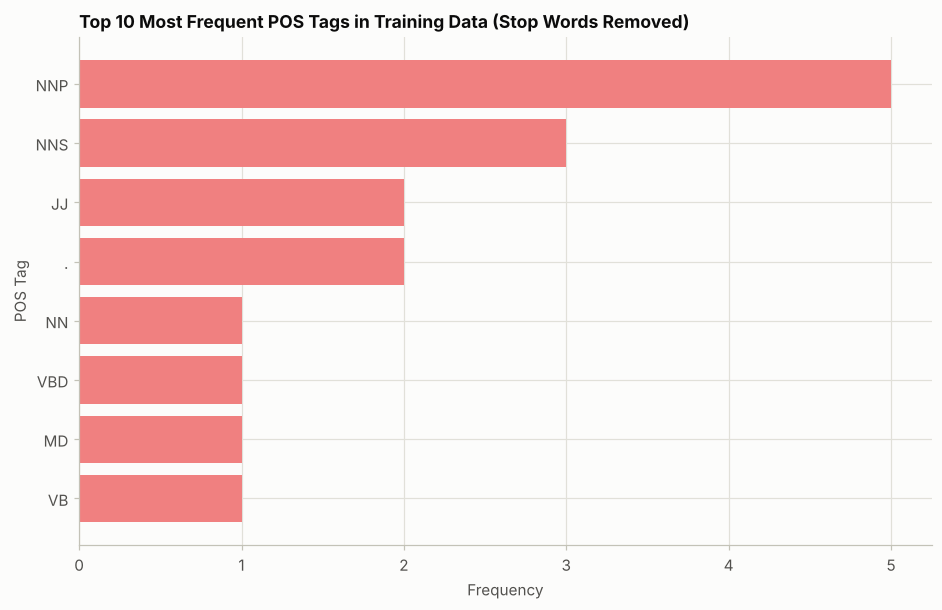

In [24]:
# BOOK CODE (pp. 228-230): visualizing POS tag frequencies (stop words removed before tagging)
# Visualizing POS tag frequencies
ensure_nltk("corpora/stopwords")  # the book calls nltk.download('stopwords', quiet=True)

# Get the set of English stop words for efficient lookup
stop_words_set = set(stopwords.words('english'))

all_individual_pos_tags = []

# Iterate through each text in X_train to extract POS tags
# X_train is assumed to be a list of strings (sentences) from previous cells.
for text_content in X_train:
    tokens = nltk.word_tokenize(text_content) # Split text into words

    # Filter out stop words. Comparison is case-insensitive.
    filtered_tokens = [token for token in tokens if token.lower() not in stop_words_set]

    # If the sentence becomes empty after stop word removal (e.g., all tokens were stop words),
    # or if the original sentence was empty, skip to the next sentence.
    if not filtered_tokens:
        continue

    # Perform Part-of-Speech tagging on the filtered tokens.
    # This returns a list of (token, TAG) tuples, e.g., [('cat', 'NN'), ('sat', 'VBD')]
    pos_tagged_tokens = nltk.pos_tag(filtered_tokens)

    # Extract and store only the POS tags (the TAG part)
    for _, tag in pos_tagged_tokens: # We only need the tag, not the token itself for this visualization
        all_individual_pos_tags.append(tag)

# Count the frequencies of all collected individual POS tags
pos_tag_counter = Counter(all_individual_pos_tags)

# Get the 10 most common POS tags and their counts (or all if fewer than 10)
top_10_pos_tags = pos_tag_counter.most_common(10)

# Check if any POS tags were found before attempting to plot
if top_10_pos_tags:
    # Unzip the list of (tag, count) tuples into two separate lists
    tags, counts = zip(*top_10_pos_tags)

    plt.figure(figsize=(10,6)) # plt is assumed to be imported as matplotlib.pyplot
    # Create a horizontal bar chart; convert tuples from zip to lists for plotting
    plt.barh(list(tags), list(counts), color='lightcoral')
    plt.xlabel('Frequency')
    plt.ylabel('POS Tag')
    plt.title('Top 10 Most Frequent POS Tags in Training Data (Stop Words Removed)')
    plt.gca().invert_yaxis() # Invert y-axis to show the most frequent item at the top
    plt.show()
else:
    # This message is displayed if X_train was empty, all tokens were stop words,
    # or no tokens remained after filtering to be tagged.
    print("No POS tags found to display. Check X_train data and stop word filtering process.")

In [25]:
# EXTRA: inspect the n-gram features and the tiny test set
features = ngram_vectorizer.get_feature_names_out()
unigrams = [f for f in features if " " not in f]
bigrams = [f for f in features if " " in f]
print(f"n-gram features: {len(features)} ({len(unigrams)} unigrams + {len(bigrams)} bigrams); train matrix {X_train_ngram.shape}, test matrix {X_test_ngram.shape}")
print("bigrams:", bigrams)
print("test sentences:", X_test)
print("non-zero cells of the test matrix:", X_test_ngram.nnz)
for row, sentence in enumerate(X_test):
    print(f"  test sentence {row}: {({str(features[j]): int(X_test_ngram[row, j]) for j in X_test_ngram[row].nonzero()[1]})}")
print("tag counts shown in the figure:", dict(pos_tag_counter))

n-gram features: 39 (20 unigrams + 19 bigrams); train matrix (2, 39), test matrix (2, 39)
bigrams: ['and of', 'ann turner', 'are the', 'chief supporters', 'civil rights', 'dan morgan', 'forget ann', 'he would', 'himself he', 'liberals are', 'morgan told', 'northern liberals', 'of civil', 'of integration', 'rights and', 'supporters of', 'the chief', 'told himself', 'would forget']
test sentences: ['He was well rid of her .', 'They have also led the nation in the direction of a welfare state .']
non-zero cells of the test matrix: 4
  test sentence 0: {'he': 1, 'of': 1}
  test sentence 1: {'of': 1, 'the': 2}
tag counts shown in the figure: {'NNP': 5, 'NNS': 3, 'JJ': 2, 'NN': 1, '.': 2, 'VBD': 1, 'MD': 1, 'VB': 1}


**Output analysis.**

* The four sentences are one training and one test sentence per genre: the training set holds *Northern liberals are the chief supporters of civil rights and of integration .* (`belles_lettres`) and *Dan Morgan told himself he would forget Ann Turner .* (`adventure`).
* The n-gram vectorizer finds **39 features**, 20 unigrams and 19 bigrams, in a 2 x 39 training matrix. The test matrix has only **4 non-zero cells** (*he* and *of* in the first test sentence, *the* (twice) and *of* in the second) and not a single bigram: the test sentences share almost nothing with the training sentences. Four sentences can demonstrate the API, and nothing more.
* The tagged output is the book's: the same tags, for example `Northern/NNP liberals/NNS are/VBP`, and the same tagged bigrams, which include the final full stop (`integration/NN ./.`). The tagger treats the full stop as a token with the tag `.`; `CountVectorizer`, on the other hand, drops punctuation, so the two kinds of bigrams are different objects.
* The bar chart (the book's Figure 9.3) rests on 16 tags: `NNP` 5, `NNS` 3, `JJ` 2, `.` 2, and `NN`, `VBD`, `MD`, `VB` once each. Proper nouns, nouns and adjectives make up 11 of the 16, in line with the book's sentence, but nothing can be concluded from two sentences; extra (c) repeats the count on the whole corpus. The full stop is among the bars because stop-word removal does not remove punctuation.
* The listing removes the stop words **before** tagging. Extra (d) shows that this lowers the tagger's accuracy.
* The text promises NER ("the three elements we just extracted"), but the listing contains no NER code; extra (f) adds it.

### Extra: experiments for recipe 3

**(a) How fast do n-grams grow?** The table counts the features of `CountVectorizer(ngram_range=(1, n))` on the 2,000 movie reviews of recipe 1, and how many of them occur in a single review.

In [26]:
# EXTRA: (a) vocabulary growth with the n-gram range (2,000 movie reviews)
ensure_nltk("corpora/movie_reviews")
from nltk.corpus import movie_reviews

reviews = [movie_reviews.raw(file_id) for file_id in movie_reviews.fileids()]
sentiment = [movie_reviews.categories(file_id)[0] for file_id in movie_reviews.fileids()]

rows = []
for n in (1, 2, 3):
    X_n = CountVectorizer(ngram_range=(1, n)).fit_transform(reviews)
    doc_freq = np.asarray((X_n > 0).sum(axis=0)).ravel()
    rows.append({"ngram_range": f"(1, {n})", "features": X_n.shape[1],
                 "in a single review": int((doc_freq == 1).sum()),
                 "share in a single review": (doc_freq == 1).mean(),
                 "features with min_df=2": int((doc_freq >= 2).sum())})
pd.DataFrame(rows).set_index("ngram_range").round(3)

,features,in a single review,share in a single review,features with min_df=2
ngram_range,,,,
"(1, 1)",39659,15572,0.393,24087
"(1, 2)",538909,399461,0.741,139448
"(1, 3)",1529707,1299909,0.850,229798


**(b) Do n-grams help a classifier?** Sentiment is a task where context should matter (*not good*). The cell scores unigrams, unigrams plus bigrams, and unigrams to trigrams (all with `min_df=2`), on counts and on binary presence, with the repeated cross-validation of recipe 1 (ten folds, the vectorizer inside the pipeline). It then lists the bigrams with the largest weights.

In [27]:
# EXTRA: (b) n-grams for sentiment classification, repeated cross-validation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv_ngram = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
fold_scores = {}
for binary in (False, True):
    for n in (1, 2, 3):
        pipeline = make_pipeline(CountVectorizer(ngram_range=(1, n), min_df=2, binary=binary), LogisticRegression(max_iter=1000))
        fold_scores[("binary" if binary else "counts", n)] = cross_val_score(pipeline, reviews, sentiment, cv=cv_ngram, n_jobs=-1)

rows = []
for (weighting, n), scores in fold_scores.items():
    reference = fold_scores[(weighting, 1)]
    rows.append({"features": weighting, "ngram_range": f"(1, {n})", "mean accuracy": scores.mean(), "std over folds": scores.std(),
                 "mean gain over unigrams": (scores - reference).mean(), "folds better than unigrams": int((scores > reference).sum())})
print(pd.DataFrame(rows).set_index(["features", "ngram_range"]).round(4).to_string())

# the bigrams with the largest weights in a binary (1, 2) model fitted on all reviews
bigram_vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
bigram_model = LogisticRegression(max_iter=1000).fit(bigram_vectorizer.fit_transform(reviews), sentiment)
names = bigram_vectorizer.get_feature_names_out()
is_bigram = np.array([" " in name for name in names])
order = np.argsort(bigram_model.coef_[0])
negative = [names[i] for i in order if is_bigram[i]][:10]
positive = [names[i] for i in order[::-1] if is_bigram[i]][:10]
print("\nbigrams that push towards 'neg':", negative)
print("bigrams that push towards 'pos':", positive)

                      mean accuracy  std over folds  mean gain over unigrams  folds better than unigrams
features ngram_range                                                                                    
counts   (1, 1)              0.8315          0.0169                   0.0000                           0
         (1, 2)              0.8480          0.0158                   0.0165                           9
         (1, 3)              0.8478          0.0163                   0.0162                           9
binary   (1, 1)              0.8542          0.0097                   0.0000                           0
         (1, 2)              0.8668          0.0174                   0.0125                           8
         (1, 3)              0.8718          0.0164                   0.0175                           9

bigrams that push towards 'neg': ['the only', 'should have', 'the worst', 'supposed to', 'have been', 'to work', 'waste of', 'to be', 'would have', 'to make']


**(c) Tagging at scale.** The book's figure rests on two sentences, which cannot support the claim that "proper nouns, nouns, and adjectives make up the majority". The cell tags **all 57,340 sentences of the Brown corpus** (1.16 million tokens) with the same tagger, keeps one tag string per document for the next experiment, and draws the book's figure again. It tags the **whole sentence first and removes stop words afterwards**; the book does the opposite, and experiment (d) measures what that costs.

tagged 57,340 sentences and 1,161,192 tokens in 500 documents


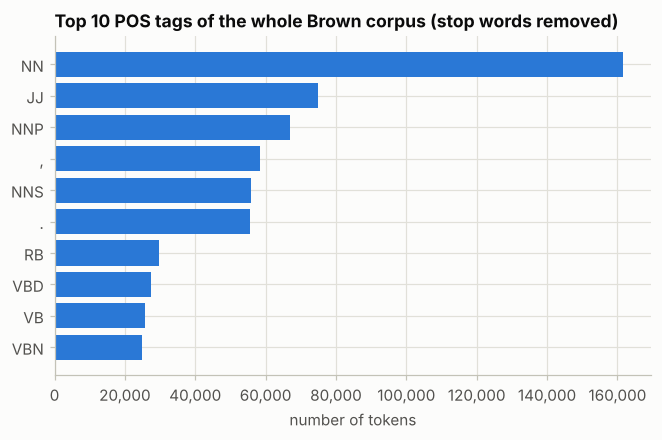

nouns (NN, NNS, NNP, NNPS): 41.7% of the 684,798 remaining tokens; adjectives (JJ, JJR, JJS): 11.5%; punctuation tags (',' and '.'): 16.6%


In [28]:
# EXTRA: (c) POS-tag the whole Brown corpus; tag frequencies without stop words
brown_ids = brown.fileids()
brown_genre = np.array([brown.categories(file_id)[0] for file_id in brown_ids])
brown_text = [" ".join(brown.words(file_id)) for file_id in brown_ids]

content_tag_counts = Counter()
brown_tag_strings = []
n_tokens = n_sentences = 0
for file_id in brown_ids:
    tags_of_document = []
    for sentence in brown.sents(file_id):
        tagged = nltk.pos_tag(sentence)                      # tag the full sentence first
        tags_of_document.extend(tag for _, tag in tagged)
        content_tag_counts.update(tag for word, tag in tagged if word.lower() not in stop_words_set)
        n_tokens += len(sentence)
        n_sentences += 1
    brown_tag_strings.append(" ".join(tags_of_document))
print(f"tagged {n_sentences:,} sentences and {n_tokens:,} tokens in {len(brown_ids)} documents")

from matplotlib.ticker import FuncFormatter

top = content_tag_counts.most_common(10)
total_content = sum(content_tag_counts.values())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([tag for tag, _ in top], [count for _, count in top], color=PALETTE[0])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{int(value):,}"))
ax.set_xlabel("number of tokens")
ax.set_title("Top 10 POS tags of the whole Brown corpus (stop words removed)")
plt.show()
nouns = sum(content_tag_counts[t] for t in ("NN", "NNS", "NNP", "NNPS"))
print(f"nouns (NN, NNS, NNP, NNPS): {nouns / total_content:.1%} of the {total_content:,} remaining tokens; adjectives (JJ, JJR, JJS): "
      f"{sum(content_tag_counts[t] for t in ('JJ', 'JJR', 'JJS')) / total_content:.1%}; punctuation tags (',' and '.'): "
      f"{(content_tag_counts[','] + content_tag_counts['.']) / total_content:.1%}")

**(d) How accurate is the tagger, and what does the book's order of operations cost?** The Brown corpus ships with **gold tags** assigned by annotators, which can be mapped to the 12-tag *universal* tagset. NLTK's tagger can output the same universal tags, so the two can be compared token by token on the first 3,000 sentences. The comparison is run for the two orders: tag the whole sentence and then drop the stop words, or (as in the book) drop the stop words and then tag what is left.

In [29]:
# EXTRA: (d) tagger agreement with the gold tags of the Brown corpus, two orders of operations
ensure_nltk("taggers/universal_tagset")

sentences = brown.sents()[:3000]
gold_sentences = brown.tagged_sents(tagset="universal")[:3000]
agree_all = total_all = 0
agree_tag_first = agree_filter_first = total_content_tokens = 0
for sentence, gold in zip(sentences, gold_sentences):
    full = nltk.pos_tag(sentence, tagset="universal")
    agree_all += sum(f[1] == g[1] for f, g in zip(full, gold))
    total_all += len(sentence)
    keep = [i for i, word in enumerate(sentence) if word.lower() not in stop_words_set]
    if not keep:
        continue
    filtered_first = nltk.pos_tag([sentence[i] for i in keep], tagset="universal")
    for position, i in enumerate(keep):
        total_content_tokens += 1
        agree_tag_first += full[i][1] == gold[i][1]
        agree_filter_first += filtered_first[position][1] == gold[i][1]

print(f"all tokens of {len(sentences):,} sentences : agreement with the gold tags {agree_all / total_all:.1%}")
print(f"the {total_content_tokens:,} non-stop-word tokens:")
print(f"  tag the sentence, then drop stop words (this notebook): {agree_tag_first / total_content_tokens:.1%}")
print(f"  drop stop words, then tag (the book)                  : {agree_filter_first / total_content_tokens:.1%}")

all tokens of 3,000 sentences : agreement with the gold tags 93.1%
the 41,497 non-stop-word tokens:
  tag the sentence, then drop stop words (this notebook): 94.0%
  drop stop words, then tag (the book)                  : 89.8%


**(e) Are tags useful as features?** The book claims that POS tagging "enables models to leverage syntactic structure". The experiment predicts the **genre** of a Brown document (15 classes) with repeated 5-fold cross-validation, from (1) the TF-IDF of its words, and (2) only the **proportions of its 44 POS tags**, a representation that contains no topic words at all. Each feature set gets its own classifier whose `C` is tuned by an inner 3-fold search inside every training fold (nested cross-validation), so that neither side profits from a lucky setting.

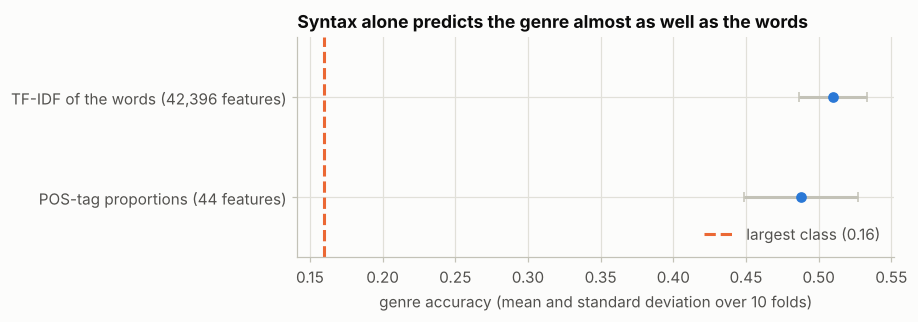

POS-tag proportions: 0.488 +- 0.039   words: 0.510 +- 0.023   chance: 0.160

mean share of a tag among all tokens of a document, in %:
            PRP  VBD    NN   JJ    IN   NNP
fiction     6.6  7.6  12.9  5.2  10.1   4.8
romance     7.7  7.3  12.1  5.5   9.4   4.7
learned     1.8  2.2  15.8  8.7  13.3   3.9
government  1.6  1.4  14.7  7.9  13.3   7.1
news        2.1  3.9  13.8  6.2  11.6  12.4


In [30]:
# EXTRA: (e) genre classification from words versus from POS-tag proportions (nested cross-validation)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

cv_genre = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
words_model = make_pipeline(TfidfVectorizer(),
                            GridSearchCV(LinearSVC(random_state=2024), {"C": [0.1, 1, 10, 100]}, cv=3))
tag_proportions = TfidfVectorizer(lowercase=False, token_pattern=r"\S+", use_idf=False, norm="l1")
tags_model = make_pipeline(tag_proportions,
                           GridSearchCV(LogisticRegression(max_iter=5000), {"C": [0.1, 1, 10, 100, 1000]}, cv=3))

scores_words = cross_val_score(words_model, brown_text, brown_genre, cv=cv_genre, n_jobs=-1)
scores_tags = cross_val_score(tags_model, brown_tag_strings, brown_genre, cv=cv_genre, n_jobs=-1)
n_tags = len(TfidfVectorizer(lowercase=False, token_pattern=r"\S+").fit(brown_tag_strings).vocabulary_)
n_words = len(TfidfVectorizer().fit(brown_text).vocabulary_)
chance = max(Counter(brown_genre).values()) / len(brown_genre)

labels_ = [f"POS-tag proportions ({n_tags} features)", f"TF-IDF of the words ({n_words:,} features)"]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.errorbar([scores_tags.mean(), scores_words.mean()], [0, 1], xerr=[scores_tags.std(), scores_words.std()],
            fmt="o", color=PALETTE[0], ecolor=AXIS, capsize=3)
ax.axvline(chance, color=PALETTE[1], linestyle="--", label=f"largest class ({chance:.2f})")
ax.set_yticks([0, 1])
ax.set_yticklabels(labels_)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("genre accuracy (mean and standard deviation over 10 folds)")
ax.set_title("Syntax alone predicts the genre almost as well as the words")
ax.legend(loc="lower right")
plt.show()
print(f"POS-tag proportions: {scores_tags.mean():.3f} +- {scores_tags.std():.3f}   words: {scores_words.mean():.3f} +- {scores_words.std():.3f}   chance: {chance:.3f}")

# what the tag proportions look like: mean share (in %) of six tags among all the tags of a document
tag_matrix = pd.DataFrame(tag_proportions.fit_transform(brown_tag_strings).toarray(), columns=tag_proportions.get_feature_names_out())
by_genre = tag_matrix.groupby(brown_genre).mean() * 100
print("\nmean share of a tag among all tokens of a document, in %:")
print(by_genre.loc[["fiction", "romance", "learned", "government", "news"], ["PRP", "VBD", "NN", "JJ", "IN", "NNP"]].round(1).to_string())

**(f) The named entities the book describes but does not extract.** NLTK's `ne_chunk` takes POS-tagged tokens and groups the proper nouns into entities. The cell runs it on the book's four sentences and on three new ones.

In [31]:
# EXTRA: (f) named entity recognition with NLTK's chunker
ensure_nltk("chunkers/maxent_ne_chunker_tab")
ensure_nltk("corpora/words")


def named_entities(sentence):
    """Return (text, label) for each entity chunk found by NLTK's ne_chunk."""
    tree = nltk.ne_chunk(nltk.pos_tag(nltk.word_tokenize(sentence)))
    return [(" ".join(word for word, tag in chunk.leaves()), chunk.label()) for chunk in tree if hasattr(chunk, "label")]


examples = texts + [
    "Maria Santos works for Google in London.",
    "The European Central Bank raised interest rates in Frankfurt on Thursday.",
    "Packt published the book in Birmingham.",
]
for sentence in examples:
    print(f"{sentence}\n    -> {named_entities(sentence)}")

Dan Morgan told himself he would forget Ann Turner .
    -> [('Dan', 'PERSON'), ('Morgan', 'PERSON'), ('Ann Turner', 'PERSON')]
He was well rid of her .
    -> []
Northern liberals are the chief supporters of civil rights and of integration .
    -> [('Northern', 'GPE')]
They have also led the nation in the direction of a welfare state .
    -> []
Maria Santos works for Google in London.
    -> [('Maria', 'PERSON'), ('Santos', 'PERSON'), ('Google', 'GPE'), ('London', 'GPE')]
The European Central Bank raised interest rates in Frankfurt on Thursday.
    -> [('European Central Bank', 'ORGANIZATION'), ('Frankfurt', 'GPE')]
Packt published the book in Birmingham.
    -> [('Packt', 'PERSON'), ('Birmingham', 'GPE')]


**Analysis of the extras.**

* **(a)** Unigrams give 39,659 features (39.3% of them in a single review). Adding bigrams multiplies the number of features by 13.6 (538,909), and 74.1% of them occur in one review only; with trigrams there are 1,529,707 features (38.6 times as many) and 85.0% occur once. `min_df=2` keeps 24,087, 139,448 and 229,798 features. N-grams add context at the price of a feature space that is mostly noise unless it is pruned.
* **(b)** On counts, adding bigrams gains **1.65 points** (0.8315 to 0.8480, better on 9 of 10 folds), and trigrams add nothing more (0.8478). On binary presence, bigrams gain 1.25 points (8 of 10 folds) and trigrams 1.75 points (0.8718, 9 of 10 folds). Combined with the binary weighting of recipe 1, n-grams lift the accuracy from 0.8315 to 0.8718, **4.0 points**. The strongest negative bigrams are expressions of disappointment (*waste of*, *the worst*, *should have*, *supposed to*, *would have*) and the strongest positive ones are *the best* and *very well*. Some of the others (*he is*, *but it*) are artifacts of how reviews are written, not sentiment.
* **(c)** The corpus has 57,340 sentences and 1,161,192 tokens; 684,798 remain after stop-word removal. Nouns (`NN`, `NNS`, `NNP`, `NNPS`) make up **41.7%** and adjectives **11.5%** of those tokens, 53.2% together: the book's sentence about "proper nouns, nouns, and adjectives" holds at scale, although "majority" is only just true. The commas and full stops are 16.6% of the remaining tokens and occupy two of the ten bars, because the stop-word list does not contain punctuation.
* **(d)** The tagger agrees with the corpus annotation on **93.1%** of all tokens (the two schemes differ in their conventions, so this understates its accuracy). On the 41,497 content words, the agreement is **94.0%** when the whole sentence is tagged and the stop words are dropped afterwards, and only **89.8%** when the stop words are dropped first, as in the book. Function words such as *the*, *of* and *was* are the context the tagger relies on, so removing them before tagging costs 4.2 points.
* **(e)** The proportions of 44 POS tags alone predict the genre with an accuracy of **0.488** (standard deviation 0.039 over the folds), against 0.510 (0.023) for the TF-IDF of 42,396 words and 0.160 for the largest class. The gap of 2.2 points is smaller than the spread between folds. A representation that contains no topic words at all comes close to the word model, which is evidence for the book's claim that tags carry syntactic structure. The table shows what they pick up: pronouns (`PRP`, 6.6% to 7.7%) and past-tense verbs (`VBD`, 7.3% to 7.6%) mark fiction and romance, against 1.6% to 1.8% pronouns in `learned` and `government` texts, which use more nouns, adjectives and prepositions (`NN`, `JJ`, `IN`); `news` stands out for its proper nouns (`NNP`, 12.4%). The experiment does not say that adding tags to the words helps; it was not tested.
* **(f)** The chunker finds the entities of the book's sentences only partly: *Ann Turner* is one `PERSON`, but *Dan* and *Morgan* (like *Maria* and *Santos*) come out as two separate chunks, and *Northern*, the first word of its sentence (tagged `NNP`), is labelled `GPE`. On the new sentences, *European Central Bank* is a correct `ORGANIZATION` and the cities are correct `GPE`s, but *Google* is labelled `GPE` and *Packt* `PERSON`. A classical chunker is a rough tool; entity features need a better model (spaCy's pipelines, for example) and a check of their output.

---
## 4. Implementing text classification models

### Summary

* Text classification "categorize[s] textual data effectively, such as sentiment analysis or topic classification". The recipe trains **Naive Bayes, a support vector machine (SVM) and logistic regression** on the same TF-IDF features and compares them.
* **Getting ready** — the `brown` corpus again, now at the document level: each of the 500 files becomes one string (`' '.join(brown.words(file_id))`), its **genre** (one of 15) is the label, and the data is split 50/50, stratified, with `random_state=2024`: 250 documents for training and 250 for testing. The book notes that `punkt_tab` may have to be downloaded.
* **How to do it** — `TfidfVectorizer()`, then `MultinomialNB()`, `SVC(random_state=2024)` and `LogisticRegression(random_state=2024, max_iter=1000)`, each evaluated with a styled `classification_report` (Figures 9.4 to 9.6) and compared in an accuracy bar chart (Figure 9.7).
* **What the book concludes** — "we are using a very small dataset (with very simple labeling)", so the models "will appear to perform better/worse than they might on real-world data". Naive Bayes "doesn't perform all that well"; SVM and logistic regression are "relatively similar in performance" but "operate differently on certain text elements"; "across all models, we can see that tokens with a higher frequency help improve inferences".
* **How it works** — Naive Bayes suits text because of "its probabilistic nature and efficiency in handling large feature spaces"; the SVM "excels at capturing complex relationships by finding optimal hyperplanes"; logistic regression "provides robust predictions and interpretable probabilities".
* **There's more** — ensembles, deep learning, hyperparameter tuning and embeddings could improve the results.

### Theory: three classifiers on a sparse, high-dimensional matrix

**Multinomial Naive Bayes.** The model assumes that, given the class $c$, the words of a document are drawn independently from a class-specific distribution $\theta_c$ over the vocabulary (the "naive" assumption). By Bayes' rule, for a document with term counts $x_1, \dots, x_{|V|}$,

$$
\log P(c \mid \mathbf{x}) = \log P(c) + \sum_{j} x_j \log \theta_{cj} + \text{const.}, \qquad
\hat\theta_{cj} = \frac{N_{cj} + \alpha}{N_c + \alpha |V|},
$$

where $N_{cj}$ is the total weight of term $j$ in the training documents of class $c$, $N_c = \sum_j N_{cj}$, and $\alpha$ is a **smoothing** constant (Laplace smoothing for $\alpha = 1$) that keeps an unseen word from giving a probability of zero. Training is one pass over the data and prediction is a sparse matrix product, hence the "efficiency in handling large feature spaces". The model was derived for **counts**. Fed with TF-IDF it still runs (the weights act as fractional counts), but then $N_c$, the total weight of a class, is small, and $\alpha |V|$ can dominate the denominator. All classes are then smoothed towards the uniform distribution. To first order, $\log(N_{cj} + \alpha) \approx \log \alpha + N_{cj} / \alpha$ for terms whose weight $N_{cj}$ is below $\alpha$, so the score of class $c$ becomes roughly proportional to $\sum_{d \in c} \mathbf{x} \cdot \mathbf{x}_d$: the **sum**, not the mean, of the similarities between the document and all training documents of the class. A sum grows with the size of the class, so the largest classes win whatever the document says. Extra (b) measures this.

**Logistic regression and the linear SVM** learn a weight vector per class and predict from a linear function of the TF-IDF vector. Logistic regression minimizes the log-loss with an $L_2$ penalty,

$$
\min_{W} \; \frac{1}{2} \lVert W \rVert_2^2 + C \sum_{i=1}^{n} \text{loss}(y_i, W \mathbf{x}_i),
$$

and the linear SVM uses the hinge loss; $C$ is the **inverse regularization strength**. Two properties of text matter:

1. **There are many more features than documents** ($p \gg n$): 30,682 columns for 250 documents. In such a space the classes are almost always linearly separable, so a weak penalty fits the training set perfectly, and generalization depends on the margin and on the penalty.
2. **TF-IDF rows have length 1.** The entries are small (most are below 0.1), so a weight vector must be **large** to produce decision values near $\pm 1$, and the penalty $\frac{1}{2} \lVert W \rVert^2$ opposes exactly that. With the default $C = 1$ the models are over-regularized for this scale. $C$ is not a universal number: it has to be tuned for the scale of the features.

**The RBF-kernel SVM** (`SVC` default) compares two documents through $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \lVert \mathbf{x} - \mathbf{x}' \rVert^2)$. For unit vectors, $\lVert \mathbf{x} - \mathbf{x}' \rVert^2 = 2(1 - \cos\theta)$, so it is a smooth function of the cosine similarity of the two documents. It suffers from the same default $C = 1$ (see Chapter 7 for the kernel theory).

**Evaluating a 15-class problem.** The 250 test documents are spread over 15 genres, from 3 (`science_fiction`) to 40 (`learned`). Per-class precision and recall rest on very few documents, so they are noisy; **accuracy** is dominated by the large classes, and the **macro F1** weights the classes equally. The baseline to beat is the share of the largest class.

### Book code (pp. 231–239)

The preparation listing probes `tokenizers/punkt` and catches `nltk.downloader.DownloadError`. That name **does not exist** in NLTK 3.10: if the legacy `punkt` package is missing, `nltk.data.find` raises a `LookupError`, the `except` clause is evaluated, and Python stops with an `AttributeError`. The listing works here only because recipe 3 downloaded `punkt` first (a clean environment that skips recipe 3 fails, which was checked). It is reproduced as printed.

In [32]:
# BOOK CODE (pp. 231-233): load the libraries, load the brown corpus at the document level, split the data
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import nltk
from nltk.corpus import brown
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Download NLTK resources (if not already downloaded)
# It's good practice to include this, though in a real notebook,
# it might be run once in a separate cell.
try:
    nltk.data.find('corpora/brown.zip')
except nltk.downloader.DownloadError:
    nltk.download('brown', quiet=True)
try:
    # Punkt is a tokenizer dependency for some NLTK corpus operations.
    nltk.data.find('tokenizers/punkt')
except nltk.downloader.DownloadError:
    nltk.download('punkt', quiet=True)

# Load the dataset from NLTK Brown corpus
document_ids = brown.fileids()
texts = [' '.join(brown.words(file_id)) for file_id in document_ids]
# Each document in Brown corpus is assigned to a category (genre).
# We use the first category as the label.
raw_labels = [brown.categories(file_id)[0] for file_id in document_ids]

# Convert string labels (categories) to numerical labels for scikit-learn
unique_raw_labels = sorted(list(set(raw_labels)))
label_to_int_mapping = {label: i for i, label in enumerate(unique_raw_labels)}
labels = [label_to_int_mapping[label] for label in raw_labels]

# Split the data
# The Brown corpus has 500 documents and 15 categories.
# The minimum number of samples per category is >20, so stratify will work fine.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, stratify=labels, random_state=2024)

In [33]:
# BOOK CODE (pp. 234-236): TF-IDF, three classifiers, and a styled classification report for each
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a Naive Bayes model
nb_clf = MultinomialNB()
nb_clf.fit(X_train_vect, y_train)

# Train an SVM model
svm_clf = SVC(random_state=2024)
svm_clf.fit(X_train_vect, y_train)

# Train a logistic regression model
lr_clf = LogisticRegression(random_state=2024, max_iter=1000)
lr_clf.fit(X_train_vect, y_train)

# Evaluate the models
models = {'Naive Bayes': nb_clf, 'SVM': svm_clf, 'Logistic Regression': lr_clf}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name} Classification Report:')
    # Generate classification report as a dictionary
    # Utilize unique_raw_labels for target_names to show actual class names
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    # Convert to DataFrame
    report_df = pd.DataFrame(report_dict).transpose()

    # Stylize the DataFrame
    styled_df = (report_df
        .style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({
            'precision': '{:.3f}',
            'recall': '{:.3f}',
            'f1-score': '{:.3f}',
            'support': '{:.0f}'
        })
    )
    display(styled_df)
    print("\n")

Naive Bayes Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,15
belles_lettres,0.173,1.000,0.295,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.556,0.500,0.526,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




SVM Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.133,0.200,15
belles_lettres,0.236,0.946,0.378,37
editorial,0.000,0.000,0.000,14
fiction,0.312,0.357,0.333,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.424,0.700,0.528,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




Logistic Regression Classification Report:


,precision,recall,f1-score,support
adventure,1.000,0.067,0.125,15
belles_lettres,0.231,0.919,0.370,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,1.000,0.056,0.105,18
humor,0.000,0.000,0.000,4
learned,0.377,0.725,0.496,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


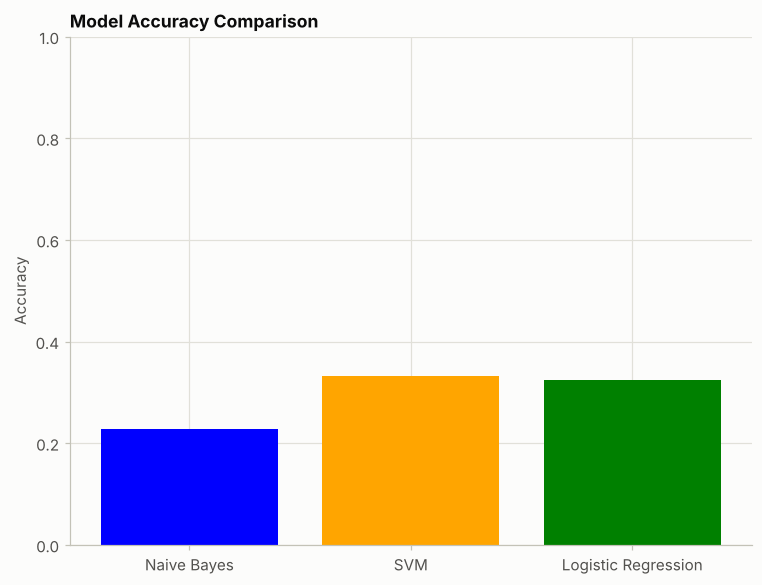

In [34]:
# BOOK CODE (pp. 238-239): visualizing classification accuracies
# Visualizing classification accuracies
model_accuracies = {}
for model_name, model_instance in models.items():
    y_pred = model_instance.predict(X_test_vect)
    # Using parameters consistent with the report generation in the preceding cells.
    # Assumes unique_raw_labels is defined and available from a previous cell,
    # as it was used in file_context_0 for generating classification reports.
    # The target_names parameter does not affect the overall 'accuracy' value but is included for consistency.
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    model_accuracies[model_name] = report_dict['accuracy']

plt.figure(figsize=(8,6))

# Plotting using the calculated accuracies
# .keys() and .values() from the same dictionary will be in corresponding orders.
plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['blue', 'orange', 'green'])
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()

**Output analysis.**

* On the 250 test documents the accuracies are **0.228** (Naive Bayes), **0.332** (SVM) and **0.324** (logistic regression). Always predicting the largest genre scores 0.160. This is the book's description: Naive Bayes is the weakest, and the SVM and logistic regression are close (two documents apart).
* **None of the three models fits even its own training data.** Their training accuracies are 0.296, 0.852 and 0.624. With 30,682 features and 250 documents, a weakly regularized model reaches 1.0. Underfitting is the first sign that the defaults, not the data, are limiting the models; extra (c) confirms it.
* Naive Bayes predicts **only two genres** (`belles_lettres` 214 times, `learned` 36 times), so its report has non-zero scores on two rows and its macro F1 is 0.055. The SVM predicts six genres and the logistic regression seven (macro F1 0.160 and 0.146).
* In the styled tables, the `accuracy` row repeats the accuracy in every column, so its "support" shows 0 instead of 250.
* The book explains the weak results by "a very small dataset (with very simple labeling)". That is only part of the story: with the right strength parameter, the same 250 documents give 0.43 to 0.49 (extra (c)).

### Extra: experiments for recipe 4

**(a) A scorecard.** The book's figures are images of styled tables; here are the numbers that matter in one table, together with the baseline that every model should beat.

In [35]:
# EXTRA: (a) scorecard of the three models and the majority-class baseline
from collections import Counter
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

rows = []
for name, model in models.items():
    predicted = model.predict(X_test_vect)
    rows.append({"model": name,
                 "train accuracy": model.score(X_train_vect, y_train),
                 "test accuracy": model.score(X_test_vect, y_test),
                 "macro F1": f1_score(y_test, predicted, average="macro", zero_division=0),
                 "genres predicted at least once": len(set(predicted))})
majority = DummyClassifier(strategy="most_frequent").fit(X_train_vect, y_train)
rows.append({"model": "majority class", "train accuracy": majority.score(X_train_vect, y_train),
             "test accuracy": majority.score(X_test_vect, y_test), "macro F1": f1_score(y_test, majority.predict(X_test_vect), average="macro", zero_division=0),
             "genres predicted at least once": 1})
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

print("\ngenres in the test set (documents):", dict(sorted(Counter(unique_raw_labels[i] for i in y_test).items(), key=lambda kv: -kv[1])))
print("what Naive Bayes predicts           :", dict(Counter(unique_raw_labels[i] for i in nb_clf.predict(X_test_vect)).most_common()))

                     train accuracy  test accuracy  macro F1  genres predicted at least once
model                                                                                       
Naive Bayes                   0.296          0.228     0.055                               2
SVM                           0.852          0.332     0.160                               6
Logistic Regression           0.624          0.324     0.146                               7
majority class                0.160          0.160     0.018                               1

genres in the test set (documents): {'learned': 40, 'belles_lettres': 37, 'lore': 24, 'news': 22, 'hobbies': 18, 'government': 15, 'adventure': 15, 'romance': 15, 'fiction': 14, 'editorial': 14, 'mystery': 12, 'religion': 9, 'reviews': 8, 'humor': 4, 'science_fiction': 3}
what Naive Bayes predicts           : {'belles_lettres': 214, 'learned': 36}


**(b) Naive Bayes by hand, and why it predicts only two genres.** The cell recomputes the model from the formula above and checks it against `MultinomialNB`. It then asks whether the **prior** is to blame (refitting with a uniform prior) and tests the first-order view of the theory: does the genre with the largest *summed* similarity to its training documents name the same genre as Naive Bayes?

In [36]:
# EXTRA: (b) multinomial Naive Bayes by hand
alpha = nb_clf.alpha
n_terms = X_train_vect.shape[1]
n_genres = len(unique_raw_labels)
y_train_arr = np.array(y_train)

class_weights = np.vstack([np.asarray(X_train_vect[y_train_arr == k].sum(axis=0)).ravel() for k in range(n_genres)])  # N_cj
theta = (class_weights + alpha) / (class_weights.sum(axis=1, keepdims=True) + alpha * n_terms)
log_prior = np.log(np.bincount(y_train_arr) / len(y_train_arr))
assert np.allclose(np.log(theta), nb_clf.feature_log_prob_)
assert np.allclose(log_prior, nb_clf.class_log_prior_)

likelihood = np.asarray(X_test_vect @ np.log(theta).T)          # sum_j x_j log theta_cj, one column per genre
joint = likelihood + log_prior
assert (joint.argmax(axis=1) == nb_clf.predict(X_test_vect)).all()
print("hand-made Naive Bayes equals MultinomialNB: True\n")

from scipy.stats import spearmanr

N_c = class_weights.sum(axis=1)
print(f"alpha * |V| in the denominator       : {alpha * n_terms:,.0f}")
print(f"total TF-IDF weight N_c of a genre    : from {N_c.min():.1f} to {N_c.max():.1f} (median {np.median(N_c):.1f}), so the smoothing mass is {alpha * n_terms / np.median(N_c):.0f} times the median N_c")
print(f"Spearman correlation of N_c with the number of training documents of the genre: {spearmanr(N_c, np.bincount(y_train_arr))[0]:.2f}")

# is the prior to blame? refit with a uniform prior
uniform_prior = MultinomialNB(fit_prior=False).fit(X_train_vect, y_train)
print(f"\npredictions with the learned prior : {dict(Counter(unique_raw_labels[i] for i in nb_clf.predict(X_test_vect)).most_common())}")
print(f"predictions with a uniform prior   : {dict(Counter(unique_raw_labels[i] for i in uniform_prior.predict(X_test_vect)).most_common())}  (test accuracy {uniform_prior.score(X_test_vect, y_test):.3f})")

# first-order view: score ~ sum over the training documents of a genre of the cosine similarity with the test document
summed_similarity = np.asarray(X_test_vect @ class_weights.T)
agreement = (summed_similarity.argmax(axis=1) == nb_clf.predict(X_test_vect)).mean()
print(f"test documents on which 'largest summed similarity' names the same genre as Naive Bayes: {agreement:.0%}")

hand-made Naive Bayes equals MultinomialNB: True

alpha * |V| in the denominator       : 30,682
total TF-IDF weight N_c of a genre    : from 45.6 to 580.6 (median 214.1), so the smoothing mass is 143 times the median N_c
Spearman correlation of N_c with the number of training documents of the genre: 0.95

predictions with the learned prior : {'belles_lettres': 214, 'learned': 36}
predictions with a uniform prior   : {'belles_lettres': 216, 'learned': 34}  (test accuracy 0.224)
test documents on which 'largest summed similarity' names the same genre as Naive Bayes: 88%


**(c) Why do all three models look weak? Regularization sweeps.** The theory predicts that the defaults ($C = 1$, $\alpha = 1$) are far too strong for TF-IDF rows. The figure scores each model over a grid of its strength parameter, with **3-fold cross-validation on the 250 training documents** (training fold in dashed orange, validation fold in solid blue). The test set is not used to choose anything. With 3 documents, `science_fiction` limits the number of folds to 3.

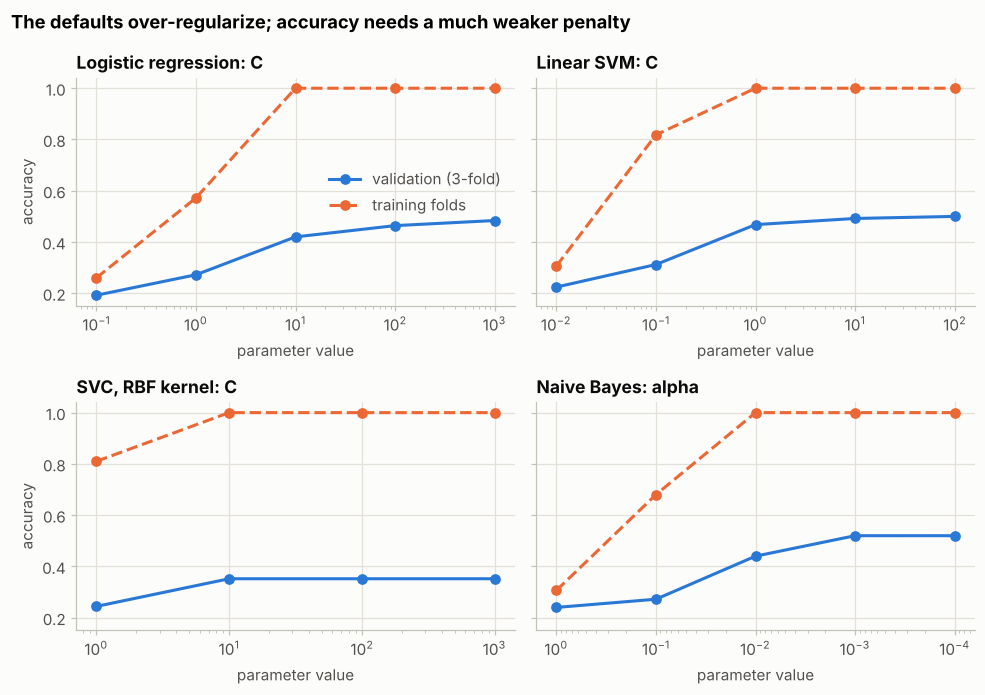

best value by validation accuracy: {'Logistic regression: C': 1000.0, 'Linear SVM: C': 100.0, 'SVC, RBF kernel: C': 10.0, 'Naive Bayes: alpha': 0.0001}
validation accuracy at that value: {'Logistic regression: C': 0.484, 'Linear SVM: C': 0.5, 'SVC, RBF kernel: C': 0.352, 'Naive Bayes: alpha': 0.52}
validation accuracy at the default (C = 1 or alpha = 1): {'Logistic regression: C': 0.272, 'Linear SVM: C': 0.468, 'SVC, RBF kernel: C': 0.244, 'Naive Bayes: alpha': 0.24}


In [37]:
# EXTRA: (c) strength of regularization against training and validation accuracy
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import LinearSVC

cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=2024)
grids = {
    "Logistic regression: C": (lambda p: LogisticRegression(C=p, max_iter=2000, random_state=2024), [0.1, 1, 10, 100, 1000]),
    "Linear SVM: C": (lambda p: LinearSVC(C=p, random_state=2024), [0.01, 0.1, 1, 10, 100]),
    "SVC, RBF kernel: C": (lambda p: SVC(C=p, random_state=2024), [1, 10, 100, 1000]),
    "Naive Bayes: alpha": (lambda p: MultinomialNB(alpha=p), [1, 0.1, 0.01, 0.001, 0.0001]),
}
sweeps = {}
for title, (make, values) in grids.items():
    rows = []
    for value in values:
        result = cross_validate(make(value), X_train_vect, y_train, cv=cv_tune, return_train_score=True, n_jobs=-1)
        rows.append({"value": value, "train": result["train_score"].mean(), "validation": result["test_score"].mean()})
    sweeps[title] = pd.DataFrame(rows).set_index("value")

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), sharey=True)
for ax, (title, frame) in zip(axes.ravel(), sweeps.items()):
    ax.plot(frame.index, frame["validation"], "o-", color=PALETTE[0], label="validation (3-fold)")
    ax.plot(frame.index, frame["train"], "o--", color=PALETTE[1], label="training folds")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("parameter value")
    if title.startswith("Naive"):
        ax.invert_xaxis()
for ax in axes[:, 0]:
    ax.set_ylabel("accuracy")
axes[0, 0].legend(loc="center right")
fig.suptitle("The defaults over-regularize; accuracy needs a much weaker penalty", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

best = {title: float(frame["validation"].idxmax()) for title, frame in sweeps.items()}
print("best value by validation accuracy:", best)
print("validation accuracy at that value:", {title: round(float(frame["validation"].max()), 3) for title, frame in sweeps.items()})
print("validation accuracy at the default (C = 1 or alpha = 1):",
      {title: round(float(frame["validation"].loc[1]), 3) for title, frame in sweeps.items()})

Now the **test set**, used once: each model refitted on the 250 training documents with the value picked by validation, next to the book's default.

In [38]:
# EXTRA: (c) continued: the validation-picked models on the test set, once
tuned = {
    "Naive Bayes": MultinomialNB(alpha=best["Naive Bayes: alpha"]),
    "SVM (RBF kernel)": SVC(C=best["SVC, RBF kernel: C"], random_state=2024),
    "Linear SVM": LinearSVC(C=best["Linear SVM: C"], random_state=2024),
    "Logistic Regression": LogisticRegression(C=best["Logistic regression: C"], max_iter=2000, random_state=2024),
}
tuned_value = {"Naive Bayes": best["Naive Bayes: alpha"], "SVM (RBF kernel)": best["SVC, RBF kernel: C"],
               "Linear SVM": best["Linear SVM: C"], "Logistic Regression": best["Logistic regression: C"]}
book_default = {"Naive Bayes": nb_clf, "SVM (RBF kernel)": svm_clf, "Logistic Regression": lr_clf}  # the book has no linear SVM
rows = []
for name, model in tuned.items():
    model.fit(X_train_vect, y_train)
    rows.append({"model": name,
                 "test accuracy, book default": book_default[name].score(X_test_vect, y_test) if name in book_default else np.nan,
                 "test accuracy, tuned": model.score(X_test_vect, y_test),
                 "tuned value": tuned_value[name]})
print(f"majority class: {majority.score(X_test_vect, y_test):.3f}")
tuned_table = pd.DataFrame(rows).set_index("model")
tuned_table["tuned value"] = tuned_table["tuned value"].map(lambda value: f"{value:g}")
tuned_table.round(3)

majority class: 0.160


,"test accuracy, book default","test accuracy, tuned",tuned value
model,,,
Naive Bayes,0.228,0.452,0.0001
SVM (RBF kernel),0.332,0.428,10
Linear SVM,NaN,0.476,100
Logistic Regression,0.324,0.492,1000


**(d) Where does the tuned model go wrong?** The confusion matrix of the tuned logistic regression, normalized by row (each row sums to 1: the share of a genre's documents sent to each predicted genre), and the per-genre scores against the number of training documents. The last line tests the book's remark that frequent classes ("tokens with a higher frequency") are learned better.

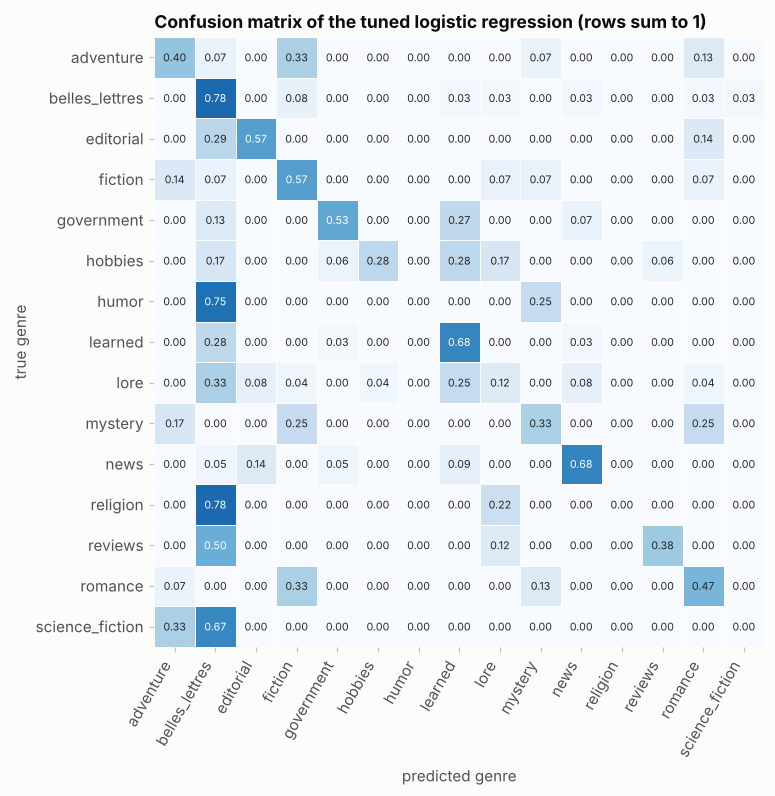

                 training documents  test documents  precision  recall    F1
learned                          40              40       0.60    0.68  0.64
belles_lettres                   38              37       0.38    0.78  0.51
lore                             24              24       0.27    0.12  0.17
news                             22              22       0.75    0.68  0.71
hobbies                          18              18       0.83    0.28  0.42
government                       15              15       0.73    0.53  0.62
fiction                          15              14       0.32    0.57  0.41
adventure                        14              15       0.50    0.40  0.44
romance                          14              15       0.41    0.47  0.44
editorial                        13              14       0.62    0.57  0.59
mystery                          12              12       0.44    0.33  0.38
reviews                           9               8       0.75    0.38  0.50

In [39]:
# EXTRA: (d) confusion matrix and per-genre scores of the tuned logistic regression
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

tuned_lr = tuned["Logistic Regression"]
predicted = tuned_lr.predict(X_test_vect)
cm = confusion_matrix(y_test, predicted, normalize="true")

fig, ax = plt.subplots(figsize=(8.6, 7.2))
sns.heatmap(cm, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="Blues", vmin=0, vmax=1, square=True, linewidths=0.4,
            linecolor=SURFACE, cbar=False, xticklabels=unique_raw_labels, yticklabels=unique_raw_labels, ax=ax)
ax.set_xlabel("predicted genre")
ax.set_ylabel("true genre")
ax.set_title("Confusion matrix of the tuned logistic regression (rows sum to 1)")
ax.grid(False)
plt.xticks(rotation=60, ha="right")
plt.show()

precision, recall, f1, support = precision_recall_fscore_support(y_test, predicted, zero_division=0)
per_genre = pd.DataFrame({"training documents": np.bincount(y_train), "test documents": support,
                          "precision": precision, "recall": recall, "F1": f1}, index=unique_raw_labels)
print(per_genre.sort_values("training documents", ascending=False).round(2).to_string())
rho, p_value = spearmanr(per_genre["training documents"], per_genre["F1"])
print(f"\nSpearman correlation between the number of training documents and the F1 of the genre: {rho:.2f} (p = {p_value:.3f})")

off = cm.copy()
np.fill_diagonal(off, 0)
for k in np.argsort(off.max(axis=1))[::-1][:4]:
    j = off[k].argmax()
    print(f"{unique_raw_labels[k]:>15} -> {unique_raw_labels[j]:<15} {off[k, j]:.0%} of its test documents")

**(e) What the model learned.** The six words with the largest coefficient for each genre in the tuned logistic regression: interpretability is the reason the book gives for choosing logistic regression.

In [40]:
# EXTRA: (e) the words with the largest weight for each genre
terms = vectorizer.get_feature_names_out()
top_words = {genre: ", ".join(terms[np.argsort(tuned_lr.coef_[k])[::-1][:6]]) for k, genre in enumerate(unique_raw_labels)}
with pd.option_context("display.max_colwidth", None):
    print(pd.Series(top_words, name="six largest coefficients").to_string())

adventure                     her, he, keith, ramey, tilghman, pamela
belles_lettres                of, hearst, his, wright, miriam, jensen
editorial                          the, podger, berlin, mr, east, has
fiction                             and, was, kate, he, hans, jessica
government         shelter, faculty, board, fiscal, foundation, corps
hobbies            prokofieff, your, hanover, juniors, site, engineer
humor                         you, arlene, moreland, said, in, comedy
learned                   af, pip, fromm, mexicans, downtown, brumidi
lore               farm, ecumenical, negroes, semitism, teeth, patent
mystery                              he, felix, car, she, you, skyros
news                      mrs, libraries, library, said, week, mantle
religion                               god, we, zen, lo, slavery, shu
reviews                                jazz, mr, sept, and, of, music
romance                             you, spencer, her, and, she, phil
science_fiction     

**Analysis of the extras.**

* **(a)** The scorecard shows the three models against the baseline: macro F1 0.055, 0.160 and 0.146 against 0.018 for the majority class. Naive Bayes predicts two genres, the largest ones.
* **(b)** The hand-made model equals `MultinomialNB`. The smoothing mass $\alpha |V|$ is 30,682, **143 times** the median total weight of a genre (214.1): the smoothed distributions are almost uniform. **The prior is not to blame**: with a uniform prior, the predictions are the same two genres in nearly the same numbers (216 and 34), with accuracy 0.224. The first-order view of the theory holds: the genre with the largest *summed* similarity to its training documents is the genre predicted by Naive Bayes for **88%** of the test documents, and the total weight $N_c$ follows the size of the genre (Spearman correlation 0.95). The two genres with the most training documents (`learned`, 40, and `belles_lettres`, 38) win. This is a consequence of feeding TF-IDF to a count model with the default $\alpha = 1$.
* **(c)** The defaults are far from the best values. With 3-fold validation, the logistic regression goes from 0.272 at `C = 1` to **0.484** at `C = 1000`, and its training folds reach 1.0 from `C = 10`; the RBF `SVC` goes from 0.244 at `C = 1` to 0.352 from `C = 10`; Naive Bayes goes from 0.240 at `alpha = 1` to **0.520** at `alpha = 0.001` and below. The linear SVM is the exception: with `C = 1` it already reaches 0.468 and it gains little (0.500 at `C = 100`). On the test set, used once, the tuned models score 0.492 (logistic regression, from 0.324), 0.476 (linear SVM, not in the book), 0.452 (Naive Bayes, from 0.228) and 0.428 (RBF `SVC`, from 0.332). The book's ranking changes: Naive Bayes, last at the defaults, ends above the RBF `SVC`. But on 250 test documents, a 95% interval for an accuracy near 0.45 is about plus or minus 6 points, so **the differences among the four tuned models cannot be ranked**. The book's picture of "a weak Naive Bayes and two similar models" came from the defaults, not from the models. The best values lie at the upper end of the grids for the logistic regression, the linear SVM and Naive Bayes (`alpha`), whose validation curves have flattened, so the grids could be extended.
* **(d)** `belles_lettres` acts as a catch-all genre: it has the best recall (0.78) and one of the worst precisions (0.38), and it absorbs 78% of the `religion` documents, 75% of the `humor` documents, 67% of the `science_fiction` documents and half of the `reviews`. `religion`, `humor` and `science_fiction` (9, 4 and 3 test documents) are never predicted correctly. The Spearman correlation between the number of training documents of a genre and its F1 is **0.61**: genres with more documents are learned better, which agrees with the book's remark that frequency helps (the book speaks of token frequency; the class frequency is what the numbers show). The Brown genres also overlap in content (`belles_lettres`, `learned`, `lore`), which limits any model.
* **(e)** Many of the largest coefficients are **proper names from one or two documents** (*keith*, *ramey* and *tilghman* for `adventure`, *kate*, *hans* and *jessica* for `fiction`, *helva*, *mercer* and *jubal* for `science_fiction`): with 3 to 40 documents per genre and 30,000 features, the model memorizes names. Some coefficients are meaningful (*god* for `religion`, *jazz* for `reviews`, *fiscal*, *board* and *faculty* for `government`, *said*, *mrs* and *week* for `news`). Coefficients of a model with far more features than documents are an interpretation aid only after a check like this one.

---
## 5. Multiclass classification strategies

### Summary

* **Multiclass classification** predicts one of more than two categories. The book recalls Chapter 6 and names three strategies: **one-vs-rest (OvR)**, **one-vs-one (OvO)** and **hierarchical classification**.
* **Getting ready** — the Brown corpus once more, at the document level, with the genre as label. The book's printed listing splits with `test_size=0.5, random_state=2024` and no stratification; the official notebook uses `test_size=0.3` with `stratify=labels` (350 training and 150 test documents). The notebook reproduces the official version, which is the one that matches the printed reports.
* **How to do it** — `TfidfVectorizer()`, then `OneVsRestClassifier(LogisticRegression(solver='liblinear'))` and `OneVsOneClassifier(LogisticRegression(solver='liblinear'))`, each evaluated with a styled `classification_report` (Figures 9.8 and 9.9).
* **What the book concludes** — "neither approach elicits great results, OvR slightly edges out OvO", and "the term romance did not elicit any predictive performance compared to OvO".
* **How it works** — OvR "builds one classifier per class, distinguishing one class from all other classes" and is "computationally efficient and straightforward"; OvO "constructs classifiers for every pair of classes, resulting in a higher number of models, but often providing better performance on balanced datasets".
* **There's more** — **hierarchical classification** "structures the classification task into levels, creating multiple classifiers in a tree-like hierarchy". The notebook builds one in extra (d).
* **Two slips in the text.** The "Getting ready" quotes NLTK's description of a corpus of "a Firefox discussion forum, conversations overheard in New York, the movie script of *Pirates of the Caribbean*, personal advertisements, and wine reviews". That is the description of NLTK's **`webtext`** corpus, not of `brown` (the official notebook still has the comment "Changed from webtext to brown"). And the comment "With 6 documents in brown, test_size=0.5 gives 3 train and 3 test samples" is left over from an earlier version; `brown` has 500 documents.

### Theory: reducing $K$ classes to binary problems

Many learners are binary (the SVM, and the liblinear solver of logistic regression for two classes). Two classical **decompositions** turn a $K$-class problem into binary ones; scikit-learn provides them as `OneVsRestClassifier` and `OneVsOneClassifier` (module `sklearn.multiclass`).

**One-vs-rest.** Train $K$ classifiers $f_1, \dots, f_K$; classifier $f_k$ separates class $k$ (positive) from **all** other classes (negative), on the whole training set. A new document gets the class with the highest score,

$$
\hat y = \arg\max_{k} f_k(\mathbf{x}).
$$

Each class has one model, which can be inspected. The drawbacks: every problem is **imbalanced** (one class against $K - 1$, so with 15 genres the positive class is about 7% of the data), and the scores of independently trained classifiers are not calibrated against each other.

**One-vs-one.** Train one classifier for **each pair** of classes, $K(K-1)/2$ in all (105 for 15 genres), each on the documents of those two classes only. Prediction is a **vote**: every classifier votes for one of its two classes, and the class with most votes wins (scikit-learn breaks ties with the summed confidences). The problems are smaller and more balanced. The cost: the number of models grows as $K^2$, and each class takes part in $K - 1$ of them, so a rare class is **outvoted** by $K - 2$ irrelevant classifiers that have never seen it.

**Cost.** OvR trains $K$ models on $n$ samples each, $Kn$ samples in all. OvO trains $K(K-1)/2$ models on $n_i + n_j$ samples each, and $\sum_{i<j} (n_i + n_j) = (K - 1)\, n$ in all. The two volumes are almost equal, but OvO splits the work into many **small** problems, which pays off for learners whose training time grows faster than linearly in the number of samples (kernel SVMs). That is why `SVC` uses OvO internally. Prediction needs $K(K-1)/2$ evaluations for OvO against $K$ for OvR.

**Other options.** Logistic regression can model all classes **jointly** with the softmax, $P(k \mid \mathbf{x}) = e^{\mathbf{w}_k \cdot \mathbf{x}} / \sum_l e^{\mathbf{w}_l \cdot \mathbf{x}}$, with no decomposition at all (the *multinomial* model of Chapter 6, which the default `lbfgs` solver of `LogisticRegression` fits). **Error-correcting output codes** (`OutputCodeClassifier`) give each class a binary code word and train one binary classifier per bit, so that a few wrong bits can be corrected.

**Hierarchical classification.** When the classes form a natural tree, train a classifier for the first level, then one per branch. Brown's genres do: the corpus manual groups nine **informative** genres (news, editorial, reviews, religion, hobbies, lore, belles lettres, government, learned) and six **imaginative** ones (fiction, mystery, science fiction, adventure, romance, humor). A two-level model first decides the group, then the genre inside it. Its errors **compound**: a document sent to the wrong group cannot be recovered at the second level.

**Metrics.** With several classes, precision, recall and F1 are computed per class, then averaged: **macro** (all classes equal), **weighted** (by support) or **micro** (pooled counts, equal to accuracy for single-label problems).

### Book code (pp. 240–244)

In [41]:
# BOOK CODE (pp. 240-241): load the brown corpus at the document level and split the data (official-notebook version)
# Load the libraries
import nltk
from nltk.corpus import brown # Changed from webtext to brown
from sklearn.model_selection import train_test_split # Ensure this is available

# Download the NLTK brown corpus if not already present
# Using quiet=True to suppress verbose download output in the notebook
try:
    _ = brown.fileids() # Check if already downloaded and accessible
except LookupError:
    nltk.download('brown', quiet=True)
except Exception: # Catch other potential NLTK setup issues
    nltk.download('brown', quiet=True)

# Load the dataset from NLTK brown corpus
file_ids = brown.fileids()
texts = [brown.raw(file_id) for file_id in file_ids]
# Use the genre of the file as its label. Each file in Brown belongs to one genre.
labels = [brown.categories(file_id)[0] for file_id in file_ids]

# Split the data
# The Brown corpus has 500 documents.
# A test_size of 0.3 will result in 350 train and 150 test samples.
# This provides significantly more samples than the previous 3 train/3 test.
# Added stratify=labels for better class distribution in splits.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.3, random_state=2024, stratify=labels)

In [42]:
# BOOK CODE (pp. 241-244): TF-IDF, one-vs-rest and one-vs-one logistic regression, styled reports
# Vectorize text using TF-IDF
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier

vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Implement One-vs-Rest classification
ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovr_clf.fit(X_train_vect, y_train)
y_pred_ovr = ovr_clf.predict(X_test_vect)

# Implement One-vs-One classification
ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovo_clf.fit(X_train_vect, y_train)
y_pred_ovo = ovo_clf.predict(X_test_vect)

# Evaluate the classifiers
# Added zero_division=0 to handle cases where precision/recall might be ill-defined
# due to no predicted samples or no true samples for a class.

print('One-vs-Rest Classification Report:')
report_ovr_dict = classification_report(y_test, y_pred_ovr, zero_division=0, output_dict=True)
report_ovr_df = pd.DataFrame(report_ovr_dict).transpose()
styled_ovr_df = (report_ovr_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr_df)
print("\n")

print('One-vs-One Classification Report:')
report_ovo_dict = classification_report(y_test, y_pred_ovo, zero_division=0, output_dict=True)
report_ovo_df = pd.DataFrame(report_ovo_dict).transpose()
styled_ovo_df = (report_ovo_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovo_df)
print("\n")

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.224,0.773,0.347,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.345,0.792,0.481,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7




One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.185,0.773,0.298,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.373,0.792,0.507,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


In [43]:
# EXTRA: inspect the two reports (the styled tables are images in the book)
for name, predicted in [("OvR", y_pred_ovr), ("OvO", y_pred_ovo)]:
    report = classification_report(y_test, predicted, zero_division=0, output_dict=True)
    scored = {genre: round(stats["f1-score"], 2) for genre, stats in report.items() if genre in set(labels) and stats["f1-score"] > 0}
    print(f"{name}: accuracy {report['accuracy']:.3f} on {len(y_test)} test documents (majority class: {max(Counter(y_test).values()) / len(y_test):.3f}); genres with F1 > 0: {scored}")

OvR: accuracy 0.307 on 150 test documents (majority class: 0.160); genres with F1 > 0: {'belles_lettres': 0.35, 'learned': 0.48, 'news': 0.67, 'romance': 0.32}
OvO: accuracy 0.273 on 150 test documents (majority class: 0.160); genres with F1 > 0: {'belles_lettres': 0.3, 'learned': 0.51, 'news': 0.53}


**Output analysis.**

* On the 150 test documents, OvR scores **0.307** (46 documents) and OvO **0.273** (41 documents); the largest genre alone would score 0.160. Both are poor, and OvR is ahead by five documents, which is the book's "OvR slightly edges out OvO".
* Only a few genres are predicted correctly at all: OvR scores on `belles_lettres`, `learned`, `news` and `romance`, OvO on the first three only. The `romance` genre has an F1 of 0.32 under OvR and of **0** under OvO, which is what the book's remark about *romance* means (its wording "compared to OvO" is garbled).
* In the styled tables, the `accuracy` row repeats the accuracy in every column, so its "support" shows 0 instead of 150.
* The models are logistic regressions with the default `C = 1` on TF-IDF rows, the weak setting of recipe 4. The comparison is between two weak models.

### Extra: experiments for recipe 5

**(a) How many models, and how much work?** The two wrappers expose their binary classifiers in `estimators_`. The cell counts them, adds up the training samples each strategy processes, and times the two fits (the timings depend on the machine).

In [44]:
# EXTRA: (a) the binary problems behind OvR and OvO
import time
from itertools import combinations

genre_names = sorted(set(labels))
y_train_arr = np.array(y_train)
n_train = len(y_train_arr)
class_sizes = {genre: int((y_train_arr == genre).sum()) for genre in genre_names}

ovr_sizes = [n_train for _ in genre_names]
ovo_sizes = [class_sizes[a] + class_sizes[b] for a, b in combinations(genre_names, 2)]
print(f"training documents per genre: {class_sizes}\n")
print(f"OvR: {len(ovr_clf.estimators_)} classifiers (= {len(genre_names)} genres), each on all {n_train} documents; {sum(ovr_sizes):,} samples processed")
print(f"OvO: {len(ovo_clf.estimators_)} classifiers (= {len(genre_names)} x {len(genre_names) - 1} / 2), each on {min(ovo_sizes)} to {max(ovo_sizes)} documents (mean {np.mean(ovo_sizes):.0f}); {sum(ovo_sizes):,} samples processed")
print(f"positive share of an OvR problem: {np.mean([class_sizes[g] / n_train for g in genre_names]):.1%} on average (smallest {min(class_sizes.values()) / n_train:.1%})")

for name, make in [("OvR", OneVsRestClassifier), ("OvO", OneVsOneClassifier)]:
    start = time.perf_counter()
    make(LogisticRegression(random_state=2024, solver="liblinear")).fit(X_train_vect, y_train)
    print(f"fit time of {name}: {time.perf_counter() - start:.2f} s")

training documents per genre: {'adventure': 20, 'belles_lettres': 53, 'editorial': 19, 'fiction': 20, 'government': 21, 'hobbies': 25, 'humor': 6, 'learned': 56, 'lore': 34, 'mystery': 17, 'news': 31, 'religion': 12, 'reviews': 12, 'romance': 20, 'science_fiction': 4}

OvR: 15 classifiers (= 15 genres), each on all 350 documents; 5,250 samples processed
OvO: 105 classifiers (= 15 x 14 / 2), each on 10 to 109 documents (mean 47); 4,900 samples processed
positive share of an OvR problem: 6.7% on average (smallest 1.1%)
fit time of OvR: 0.32 s
fit time of OvO: 0.58 s


**(b) Is the book's ranking real?** The book's two reports come from one split of 150 test documents. The next experiment compares six strategies (eight models, since OvR and OvO appear at two values of `C`) with **repeated stratified 5-fold cross-validation** (two repeats) over all 500 documents, the vectorizer inside the pipeline, once with the book's default $C = 1$ and once with the stronger $C = 100$ that recipe 4 favours for TF-IDF features. `SVC` and `LinearSVC` are included because they implement OvO and OvR internally.

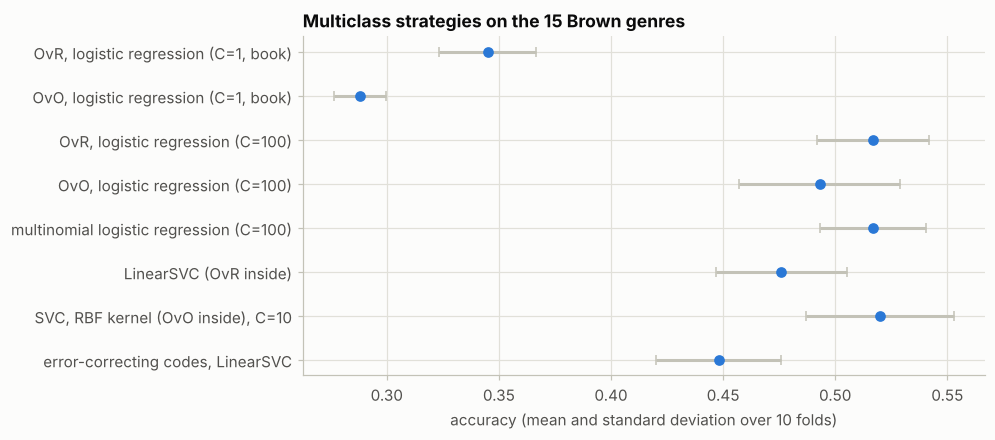

OvR minus OvO at C=1  : +0.057, OvR better on 10 of 10 folds
OvR minus OvO at C=100: +0.024, OvR better on 6 of 10 folds


,mean accuracy,std over folds
"OvR, logistic regression (C=1, book)",0.345,0.022
"OvO, logistic regression (C=1, book)",0.288,0.012
"OvR, logistic regression (C=100)",0.517,0.025
"OvO, logistic regression (C=100)",0.493,0.036
multinomial logistic regression (C=100),0.517,0.024
LinearSVC (OvR inside),0.476,0.029
"SVC, RBF kernel (OvO inside), C=10",0.520,0.033
"error-correcting codes, LinearSVC",0.448,0.028


In [45]:
# EXTRA: (b) six multiclass strategies by repeated cross-validation, over all 500 documents
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.multiclass import OutputCodeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC

cv_multi = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
liblinear = lambda C: LogisticRegression(solver="liblinear", C=C, random_state=2024)
strategies = {
    "OvR, logistic regression (C=1, book)": OneVsRestClassifier(liblinear(1)),
    "OvO, logistic regression (C=1, book)": OneVsOneClassifier(liblinear(1)),
    "OvR, logistic regression (C=100)": OneVsRestClassifier(liblinear(100)),
    "OvO, logistic regression (C=100)": OneVsOneClassifier(liblinear(100)),
    "multinomial logistic regression (C=100)": LogisticRegression(C=100, max_iter=2000),
    "LinearSVC (OvR inside)": LinearSVC(random_state=2024),
    "SVC, RBF kernel (OvO inside), C=10": SVC(C=10),
    "error-correcting codes, LinearSVC": OutputCodeClassifier(LinearSVC(random_state=2024), code_size=2, random_state=2024),
}
strategy_scores = {}
for name, estimator in strategies.items():
    strategy_scores[name] = cross_val_score(make_pipeline(TfidfVectorizer(), estimator), texts, labels, cv=cv_multi, n_jobs=-1)

summary = pd.DataFrame({"mean accuracy": {k: v.mean() for k, v in strategy_scores.items()},
                        "std over folds": {k: v.std() for k, v in strategy_scores.items()}})
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(summary["mean accuracy"], range(len(summary)), xerr=summary["std over folds"], fmt="o", color=PALETTE[0], ecolor=AXIS, capsize=3)
ax.set_yticks(range(len(summary)))
ax.set_yticklabels(summary.index)
ax.invert_yaxis()
ax.set_xlabel("accuracy (mean and standard deviation over 10 folds)")
ax.set_title("Multiclass strategies on the 15 Brown genres")
plt.show()
ovr1, ovo1 = strategy_scores["OvR, logistic regression (C=1, book)"], strategy_scores["OvO, logistic regression (C=1, book)"]
ovr100, ovo100 = strategy_scores["OvR, logistic regression (C=100)"], strategy_scores["OvO, logistic regression (C=100)"]
print(f"OvR minus OvO at C=1  : {(ovr1 - ovo1).mean():+.3f}, OvR better on {int((ovr1 > ovo1).sum())} of 10 folds")
print(f"OvR minus OvO at C=100: {(ovr100 - ovo100).mean():+.3f}, OvR better on {int((ovr100 > ovo100).sum())} of 10 folds")
summary.round(3)

**(c) The book's own split, unstratified.** The printed listing uses `test_size=0.5` without `stratify`. Do the reports change?

In [46]:
# EXTRA: (c) the printed listing's split (50/50, not stratified) with the same two strategies
X_tr, X_te, y_tr, y_te = train_test_split(texts, labels, test_size=0.5, random_state=2024)
vec = TfidfVectorizer()
A, B = vec.fit_transform(X_tr), vec.transform(X_te)
for name, make in [("OvR", OneVsRestClassifier), ("OvO", OneVsOneClassifier)]:
    model = make(LogisticRegression(random_state=2024, solver="liblinear")).fit(A, y_tr)
    print(f"{name}: test accuracy {model.score(B, y_te):.3f} on {len(y_te)} documents")
print(f"majority class: {max(Counter(y_te).values()) / len(y_te):.3f}")

OvR: test accuracy 0.272 on 250 documents
OvO: test accuracy 0.264 on 250 documents
majority class: 0.148


**(d) A two-level hierarchy.** The `TwoLevel` classifier below first predicts whether a document is informative or imaginative, then predicts its genre with a classifier trained only on that group. It is compared with the flat multinomial logistic regression of extra (b), on the same folds.

In [47]:
# EXTRA: (d) hierarchical classification with the informative / imaginative split of the Brown corpus
from sklearn.base import BaseEstimator, ClassifierMixin, clone

INFORMATIVE = {"news", "editorial", "reviews", "religion", "hobbies", "lore", "belles_lettres", "government", "learned"}


class TwoLevel(BaseEstimator, ClassifierMixin):
    """Predict the group first, then the genre with a classifier trained on that group's documents only."""

    def __init__(self, estimator=None):
        self.estimator = estimator

    def fit(self, X, y):
        y = np.asarray(y)
        group = np.where(np.isin(y, list(INFORMATIVE)), "informative", "imaginative")
        self.classes_ = np.unique(y)
        self.top_ = clone(self.estimator).fit(X, group)
        self.sub_ = {g: clone(self.estimator).fit(X[group == g], y[group == g]) for g in ("informative", "imaginative")}
        return self

    def predict(self, X):
        group = self.top_.predict(X)
        out = np.empty(X.shape[0], dtype=object)
        for g, model in self.sub_.items():
            if (group == g).any():
                out[group == g] = model.predict(X[group == g])
        return out.astype(str)


two_level = TwoLevel(LogisticRegression(C=100, max_iter=2000))
two_level_scores = cross_val_score(make_pipeline(TfidfVectorizer(), two_level), texts, labels, cv=cv_multi, n_jobs=-1)
flat_scores = strategy_scores["multinomial logistic regression (C=100)"]

groups = np.where(np.isin(labels, list(INFORMATIVE)), "informative", "imaginative")
top_scores = cross_val_score(make_pipeline(TfidfVectorizer(), LogisticRegression(C=100, max_iter=2000)), texts, groups, cv=cv_multi, n_jobs=-1)
print(f"documents per group     : {dict(Counter(groups.tolist()))}")
print(f"first level (group)     : accuracy {top_scores.mean():.3f} +- {top_scores.std():.3f}")
print(f"two-level, 15 genres    : accuracy {two_level_scores.mean():.3f} +- {two_level_scores.std():.3f}")
print(f"flat multinomial, 15    : accuracy {flat_scores.mean():.3f} +- {flat_scores.std():.3f}")
print(f"two-level minus flat    : {(two_level_scores - flat_scores).mean():+.4f}, better on {int((two_level_scores > flat_scores).sum())} of 10 folds")

documents per group     : {'informative': 374, 'imaginative': 126}
first level (group)     : accuracy 0.962 +- 0.016
two-level, 15 genres    : accuracy 0.514 +- 0.025
flat multinomial, 15    : accuracy 0.517 +- 0.024
two-level minus flat    : -0.0030, better on 3 of 10 folds


**Analysis of the extras.**

* **(a)** OvR fits 15 classifiers and OvO fits 105. Each OvR problem uses all 350 training documents, with a positive class of 6.7% on average and 1.1% for `science_fiction` (4 documents); each OvO problem uses between 10 and 109 documents (47 on average). The total number of samples processed is almost the same (5,250 against 4,900), as the theory says, but OvO splits it into seven times as many models, and its fit took about twice as long as OvR's in this run (the printed times depend on the machine).
* **(b)** The book's ordering is real but small. With the book's `C = 1`, OvR beats OvO by **5.7 points** (0.345 against 0.288), on all ten folds. With `C = 100`, the gap shrinks to 2.4 points (0.517 against 0.493), with OvR ahead on only six folds: within the noise (standard deviations 0.025 and 0.036). The book's remark that OvO "often" does better "on balanced datasets" is not supported here, but the genres are far from balanced (4 to 56 training documents), and a rare class takes part in 14 binary problems in which it is outvoted by the 13 problems that have never seen it. The **multinomial** logistic regression, which needs no decomposition, matches OvR (0.517). The `SVC` (0.520), the multinomial model and OvR at `C = 100` (0.517 each) are indistinguishable; `LinearSVC` (0.476) and the error-correcting codes (0.448) are lower, by 4 to 7 points, which is one to two standard deviations. What dominates is **regularization**: going from `C = 1` to `C = 100` adds 17 points to OvR, three times the gap between the strategies.
* **(c)** With the printed listing's unstratified 50/50 split, the ordering is the same and the gap is two documents (0.272 against 0.264, on 250 test documents; majority class 0.148).
* **(d)** The first level separates the 374 informative documents from the 126 imaginative ones with an accuracy of 0.962. The two-level model scores 0.514, the flat multinomial model 0.517: a tie (the two-level model is better on 3 of 10 folds). The flat model already separates the groups well, and the confusions that limit the accuracy (`learned`, `lore`, `belles_lettres`) are inside the informative group, where the hierarchy does not help. A hierarchy pays off for interpretation, for cost with very many labels, and when the groups are easy to separate and the within-group classes are not; it does not remove the hard confusions.

---
## 6. Evaluating text models

### Summary

* Evaluating a text classifier uses precision, recall, the F1 score and the **confusion matrix**. The book adds that evaluating large language models "requires far more complex techniques", which are out of scope.
* **Getting ready** — the 2,000 `movie_reviews`, each as a list of words with its label, **shuffled** with `random.seed(2024)`, joined back into strings, and split 50/50 with `random_state=2024` (1,000 reviews for training, 1,000 for testing).
* **How to do it** — TF-IDF, then `LogisticRegression(random_state=2024)`. The listing prints the **weighted** precision, recall and F1, a `classification_report` as a styled DataFrame, and a confusion matrix drawn with `seaborn.heatmap`.
* **How it works** — *precision* "measures the accuracy of positive predictions", *recall* (sensitivity) "assesses the ability to identify positive instances", the *F1-score* "provides a balanced measure by combining precision and recall", and the *confusion matrix* "visually represent[s] the accuracy of predictions for each class". The book concludes that the model "performs well" and identifies "both positive and negative reviews ... with similar levels of accuracy".
* **There's more** — ROC curves, AUC and cross-validation give further insight, "especially for binary classification tasks".
* **Hands-on exercises** — seven steps: train a classifier, evaluate it with precision, recall, F1 and a confusion matrix, visualize, and add other metrics and cross-validation.
* **A slip in the listing.** A comment says that `confusion_matrix` "computes class-wise accuracy"; it counts documents (a matrix normalized by row would give the class-wise recall).

### Theory: the confusion matrix and the metrics derived from it

**Confusion matrix.** For two classes, with *positive* the class of interest, the matrix counts the four outcomes: true positives (TP), false positives (FP), false negatives (FN) and true negatives (TN). With $n = \text{TP} + \text{FP} + \text{FN} + \text{TN}$,

$$
\text{accuracy} = \frac{\text{TP} + \text{TN}}{n}, \quad
\text{precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}, \quad
\text{recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \quad
F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}} .
$$

Precision answers "of the documents I called positive, how many are?", recall answers "of the positives, how many did I find?", and $F_1$ is their **harmonic mean**, which is low if either one is low. For several classes, the metrics are computed for each class against the others and then averaged:

* **macro** — the plain mean over the classes (all classes count equally);
* **weighted** — the mean weighted by the support $n_c$ of each class (the book's choice);
* **micro** — pooled counts; for single-label problems, micro precision, recall and $F_1$ all equal the accuracy.

**Weighted recall is the accuracy.** With $\text{TP}_c$ and $n_c$ the true positives and the support of class $c$,

$$
\text{recall}_{\text{weighted}} = \sum_{c} \frac{n_c}{n} \cdot \frac{\text{TP}_c}{n_c} = \frac{\sum_c \text{TP}_c}{n} = \text{accuracy} .
$$

So the book's "Recall: 0.803" is the accuracy, and on a balanced two-class problem the three weighted metrics are nearly the same number.

**Uncertainty.** A test accuracy of $\hat p$ on $n$ test documents is a binomial proportion with a standard error of $\sqrt{\hat p (1 - \hat p)/n}$: about 1.3 points for $\hat p = 0.8$ and $n = 1000$. The **Wilson interval**,

$$
\frac{\hat p + \frac{z^2}{2n} \pm z \sqrt{\frac{\hat p (1 - \hat p)}{n} + \frac{z^2}{4 n^2}}}{1 + \frac{z^2}{n}}, \qquad z = 1.96,
$$

is a 95% confidence interval that behaves well for proportions near 0 or 1 and for small $n$. A difference of one or two points between two models on one test set is within this noise.

**Threshold-free view: ROC and precision-recall.** A classifier outputs a score and a threshold turns it into a label. The **ROC curve** plots the true-positive rate (recall) against the false-positive rate over all thresholds, and the **area under it (AUC)** is the probability that a random positive document scores higher than a random negative one. The **precision-recall curve** is preferred when the positive class is rare. Both are limited to binary problems unless a class is taken against the rest.

**Cross-validation** repeats the split $k$ times and averages, which removes the dependence on one split; it is the answer to the book's "There's more".

### Book code (pp. 245–249)

In [48]:
# BOOK CODE (pp. 245-246): load the libraries, load movie_reviews as word lists, shuffle, split the data
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import movie_reviews
import random

# Download NLTK data (movie_reviews corpus) if not already downloaded
try:
    # Check if the corpus is accessible
    movie_reviews.categories()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append((list(movie_reviews.words(fileid)), category))

# Shuffle the documents for better splitting.
# Using a fixed seed for reproducibility, consistent with random_state in train_test_split.
random.seed(2024)
random.shuffle(documents)

# Prepare texts (joining words into strings) and labels
texts = [" ".join(words) for words, category in documents]
labels = [category for words, category in documents]

# Split the data
# Kept test_size and random_state as in the original selection
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

Precision: 0.8034174884733607
Recall: 0.803
F1 Score: 0.8029765558512367

Classification Report:


,precision,recall,f1-score,support
neg,0.791016,0.818182,0.804369,495.000000
pos,0.815574,0.788119,0.801611,505.000000
accuracy,0.803000,0.803000,0.803000,0.803000
macro avg,0.803295,0.803150,0.802990,1000.000000
weighted avg,0.803417,0.803000,0.802977,1000.000000


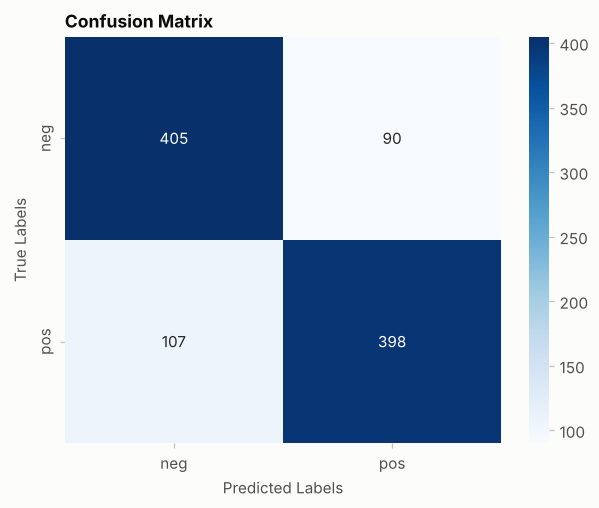

In [49]:
# BOOK CODE (pp. 247-248): TF-IDF, logistic regression, weighted metrics, classification report, confusion matrix
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a logistic regression classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train_vect, y_train)

# Make predictions
y_pred = clf.predict(X_test_vect)

# Evaluate the model
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

# Generate classification report as a styled DataFrame
report_dict = classification_report(y_test, y_pred, labels=clf.classes_, target_names=clf.classes_, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()

print("\nClassification Report:")
display(report_df.style.set_caption("Classification Report"))

# Generate and visualize a confusion matrix
# The confusion_matrix function computes class-wise accuracy.
# labels=clf.classes_ ensures the matrix rows/columns follow a consistent order.
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

**Output analysis.**

* The three printed numbers **reproduce the book's output exactly**: precision 0.8034, recall 0.803 and F1 0.8030.
* The confusion matrix counts 405 negative reviews found and 90 sent to `pos`, 398 positive reviews found and 107 sent to `neg`. Per class, `neg` has a precision of 0.79 and a recall of 0.82, and `pos` has 0.82 and 0.79. This is the book's "similar levels of accuracy" for the two classes.
* The recall of 0.803 is the **accuracy**, (405 + 398) / 1000, as the theory predicts for the weighted average.
* The book calls the result good. On a balanced problem, where guessing gives 0.5, 0.803 is solid, but 197 of the 1,000 reviews are wrong; the extras measure how far to trust the number.
* In the styled report, the `accuracy` row repeats the accuracy in every column.

### Extra: experiments for recipe 6

**(a) The metrics from the confusion matrix, by hand, and the three averages.** The cell recomputes the per-class precision, recall and $F_1$ from the four counts, and shows that weighted recall equals the accuracy, as derived above.

In [50]:
# EXTRA: (a) the metrics recomputed from the confusion matrix, and the three averaging modes
(tn, fp), (fn, tp) = cm          # rows = true class (neg, pos), columns = predicted class
n_test = cm.sum()
by_hand = {
    "neg": {"precision": tn / (tn + fn), "recall": tn / (tn + fp)},
    "pos": {"precision": tp / (tp + fp), "recall": tp / (tp + fn)},
}
for stats in by_hand.values():
    stats["F1"] = 2 * stats["precision"] * stats["recall"] / (stats["precision"] + stats["recall"])
print(f"confusion matrix (rows true, columns predicted): TN={tn} FP={fp} FN={fn} TP={tp}")
print(pd.DataFrame(by_hand).T.round(4).to_string())
assert np.isclose(by_hand["pos"]["precision"], report_dict["pos"]["precision"])
assert np.isclose(by_hand["neg"]["recall"], report_dict["neg"]["recall"])

accuracy = (tn + tp) / n_test
print(f"\naccuracy: {accuracy:.4f}")
for average in ("micro", "macro", "weighted"):
    print(f"{average:>8}: precision {precision_score(y_test, y_pred, average=average):.4f}   recall {recall_score(y_test, y_pred, average=average):.4f}   F1 {f1_score(y_test, y_pred, average=average):.4f}")
print(f"classes in the test set: { {str(k): int(v) for k, v in zip(*np.unique(y_test, return_counts=True))} }")

confusion matrix (rows true, columns predicted): TN=405 FP=90 FN=107 TP=398
     precision  recall      F1
neg     0.7910  0.8182  0.8044
pos     0.8156  0.7881  0.8016

accuracy: 0.8030
   micro: precision 0.8030   recall 0.8030   F1 0.8030
   macro: precision 0.8033   recall 0.8032   F1 0.8030
weighted: precision 0.8034   recall 0.8030   F1 0.8030
classes in the test set: {'neg': 495, 'pos': 505}


**(b) How certain is "0.803"?** The 95% Wilson interval for the accuracy on 1,000 test reviews, compared with the spread of the accuracy over repeated 5-fold cross-validation on all 2,000 reviews (two repeats, the vectorizer inside the pipeline, the book's default $C = 1$).

In [51]:
# EXTRA: (b) confidence interval of the test accuracy, and cross-validation
from scipy.stats import beta
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

z = 1.96
centre = (accuracy + z**2 / (2 * n_test)) / (1 + z**2 / n_test)
half = z * np.sqrt(accuracy * (1 - accuracy) / n_test + z**2 / (4 * n_test**2)) / (1 + z**2 / n_test)
successes = int(round(accuracy * n_test))
exact = (beta.ppf(0.025, successes, n_test - successes + 1), beta.ppf(0.975, successes + 1, n_test - successes))
print(f"test accuracy {accuracy:.3f} on {n_test} reviews")
print(f"  standard error          : {np.sqrt(accuracy * (1 - accuracy) / n_test):.4f}")
print(f"  95% Wilson interval     : {centre - half:.3f} to {centre + half:.3f}")
print(f"  95% Clopper-Pearson     : {exact[0]:.3f} to {exact[1]:.3f}")

cv_eval = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
cv_scores = cross_val_score(make_pipeline(TfidfVectorizer(), LogisticRegression(random_state=2024)), texts, labels, cv=cv_eval, n_jobs=-1)
print(f"\n5-fold cross-validation, 2 repeats, 1,600 training reviews per fold: {cv_scores.mean():.3f} +- {cv_scores.std():.3f} (min {cv_scores.min():.3f}, max {cv_scores.max():.3f})")

test accuracy 0.803 on 1000 reviews
  standard error          : 0.0126
  95% Wilson interval     : 0.777 to 0.826
  95% Clopper-Pearson     : 0.777 to 0.827

5-fold cross-validation, 2 repeats, 1,600 training reviews per fold: 0.823 +- 0.011 (min 0.797, max 0.838)


**(c) A threshold-free view.** The logistic regression produces a score for every review (`decision_function`). The ROC curve and the AUC use all possible thresholds; the dot marks the threshold 0 that `predict` uses.

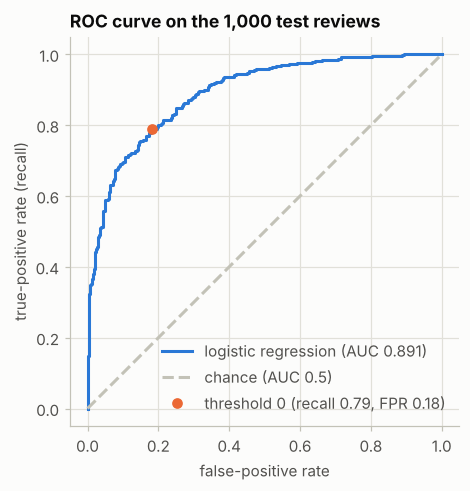

AUC 0.891, average precision 0.897


In [52]:
# EXTRA: (c) ROC curve and the area under it
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

scores = clf.decision_function(X_test_vect)               # positive score = 'pos'
is_pos = (np.array(y_test) == "pos").astype(int)
fpr, tpr, thresholds = roc_curve(is_pos, scores)
auc = roc_auc_score(is_pos, scores)
at_zero = np.argmin(np.abs(thresholds))

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot(fpr, tpr, color=PALETTE[0], label=f"logistic regression (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=AXIS, linestyle="--", label="chance (AUC 0.5)")
ax.plot(fpr[at_zero], tpr[at_zero], "o", color=PALETTE[1], label=f"threshold 0 (recall {tpr[at_zero]:.2f}, FPR {fpr[at_zero]:.2f})")
ax.set_xlabel("false-positive rate")
ax.set_ylabel("true-positive rate (recall)")
ax.set_title("ROC curve on the 1,000 test reviews")
ax.set_aspect("equal")
ax.legend(loc="lower right")
plt.show()
print(f"AUC {auc:.3f}, average precision {average_precision_score(is_pos, scores):.3f}")

**(d) What did the model learn?** The words with the largest and smallest coefficients, and a check on the distribution of review lengths, which a bag-of-words model can pick up without understanding anything.

In [53]:
# EXTRA: (d) the largest coefficients of the logistic regression, and review lengths
terms = vectorizer.get_feature_names_out()
order = np.argsort(clf.coef_[0])
print("towards 'neg':", [terms[i] for i in order[:15]])
print("towards 'pos':", [terms[i] for i in order[::-1][:15]])

length = np.array([len(text.split()) for text in texts])
is_pos_all = np.array(labels) == "pos"
print(f"\nmean review length in words: positive {length[is_pos_all].mean():.0f}, negative {length[~is_pos_all].mean():.0f}")
print(f"training accuracy of the model: {clf.score(X_train_vect, y_train):.3f}  (test: {clf.score(X_test_vect, y_test):.3f})")

towards 'neg': ['bad', 'movie', 'this', 'plot', 'boring', 'worst', 'there', 'have', 'no', 'stupid', 'supposed', 'nothing', 'only', 'any', 'why']
towards 'pos': ['and', 'is', 'as', 'his', 'life', 'war', 'mulan', 'great', 'truman', 'very', 'of', 'men', 'true', 'many', 'jackie']

mean review length in words: positive 833, negative 751
training accuracy of the model: 0.964  (test: 0.803)


**(e) Is it a matter of data or of regularization?** A learning curve (5-fold cross-validation on all reviews) with the book's $C = 1$ and with $C = 10$, which recipe 4 suggests for TF-IDF features.

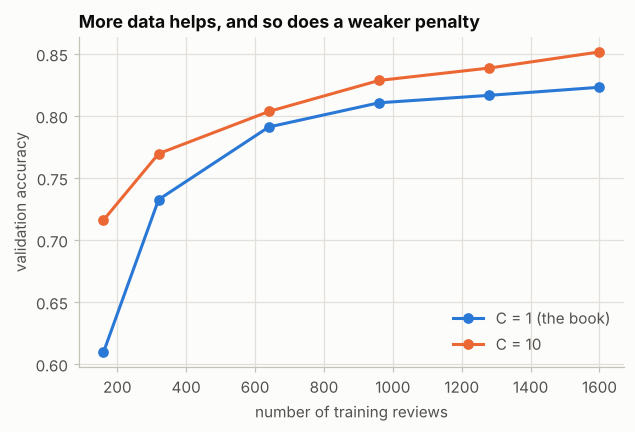

{'C=1': [0.61, 0.732, 0.791, 0.81, 0.816, 0.823], 'C=10': [0.716, 0.769, 0.803, 0.829, 0.839, 0.852]}
training sizes: [160, 320, 640, 960, 1280, 1600]


In [54]:
# EXTRA: (e) learning curves for C = 1 (the book) and C = 10
from sklearn.model_selection import StratifiedKFold, learning_curve

sizes = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
cv_learn = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
curves = {}
for C in (1, 10):
    n_train_docs, _, validation = learning_curve(make_pipeline(TfidfVectorizer(), LogisticRegression(C=C, max_iter=2000, random_state=2024)),
                                                 texts, labels, train_sizes=sizes, cv=cv_learn, n_jobs=-1)
    curves[C] = validation.mean(axis=1)

fig, ax = plt.subplots(figsize=(6.4, 3.9))
ax.plot(n_train_docs, curves[1], "o-", color=PALETTE[0], label="C = 1 (the book)")
ax.plot(n_train_docs, curves[10], "o-", color=PALETTE[1], label="C = 10")
ax.set_xlabel("number of training reviews")
ax.set_ylabel("validation accuracy")
ax.set_title("More data helps, and so does a weaker penalty")
ax.legend(loc="lower right")
plt.show()
print({f"C={C}": [round(float(v), 3) for v in curve] for C, curve in curves.items()})
print("training sizes:", [int(n) for n in n_train_docs])

**(f) Where does the model fail?** The test reviews that the model gets wrong with the highest confidence (the largest absolute score), as short excerpts.

In [55]:
# EXTRA: (f) the most confident mistakes on the test set
wrong = np.where(np.array(y_pred) != np.array(y_test))[0]
worst = wrong[np.argsort(-np.abs(scores[wrong]))[:4]]
print(f"{len(wrong)} mistakes on {len(y_test)} test reviews; the 4 most confident ones:\n")
for i in worst:
    excerpt = " ".join(X_test[i].split()[:28])
    print(f"true {y_test[i]}, predicted {y_pred[i]}, score {scores[i]:+.2f}\n    {excerpt} ...")

197 mistakes on 1000 test reviews; the 4 most confident ones:

true neg, predicted pos, score +0.78
    weighed down by tired plot lines and spielberg ' s reliance on formulas , _saving private ryan_ is a mediocre film which nods in the direction of realism ...
true pos, predicted neg, score -0.68
    plot : a human space astronaut accidentally falls upon a planet ruled by apes . he is taken prisoner along with some other humans , and tries his ...
true pos, predicted neg, score -0.67
    a big surprise to me . the good trailer had hinted that they pulled the impossible off , but making a blues brothers movie without jake blues ( ...
true pos, predicted neg, score -0.64
    a couple of months ago , when i first downloaded the face / off trailer from the net , my initial reaction was a fourteen carrot gold ' ...


**Analysis of the extras.**

* **(a)** The by-hand precision, recall and $F_1$ equal the report's. The micro average of all three metrics is the accuracy, 0.8030. The macro and weighted averages (0.8033, 0.8032, 0.8030 and 0.8034, 0.8030, 0.8030) differ from it only in the fourth decimal, because the two classes are almost equal in size (495 and 505). The three averaging modes only diverge on imbalanced data (as in recipe 4, where the macro F1 was a fraction of the accuracy).
* **(b)** The standard error of the accuracy is 1.26 points, the 95% Wilson interval runs from **0.777 to 0.826** and the exact Clopper-Pearson interval from 0.777 to 0.827. "0.803" therefore means "somewhere between 0.78 and 0.83". Repeated cross-validation, with 1,600 training reviews per fold, gives 0.823 with a standard deviation of 0.011 (from 0.797 to 0.838), which contains the test accuracy. It is higher in part because each fold trains on more reviews than the 1,000 of the book's split, as extra (e) shows.
* **(c)** The AUC is **0.891** and the average precision is 0.897. At the threshold that `predict` uses (a score of 0), the classifier finds 79% of the positive reviews and wrongly accepts 18% of the negative ones; moving the threshold slides along the curve.
* **(d)** Many of the strongest words are sentiment words (*bad*, *boring*, *worst*, *stupid*, *nothing* towards `neg`; *great*, *very*, *true* towards `pos`), but the list also holds function words (*and*, *is*, *as*, *of*, *his* towards `pos`, *this*, *there*, *have* towards `neg`) and words that look like film titles or character names (*mulan*, *truman*, *jackie*), which the model memorizes from the reviews of particular films and which will not transfer. Positive reviews are 11% longer than negative ones (833 against 751 words on average), a cue a bag-of-words model picks up through the function words. The training accuracy is 0.964 against a test accuracy of 0.803: despite the penalty, the model fits much of the training set by memorization.
* **(e)** With 160 reviews the accuracy is 0.610 (the book's `C = 1`) and 0.716 (`C = 10`); with 1,600 reviews it is 0.823 and 0.852. Both curves still rise at the right end (the last step adds 0.7 and 1.3 points), so more data would help. The weaker penalty `C = 10` is better at every size, by 3 points at the full size, the same lesson as recipe 4.
* **(f)** The model makes 197 mistakes on the 1,000 test reviews. The three most confident mistakes on positive reviews begin with a plot summary or with an anecdote about a trailer, so their first words carry little evidence of the verdict; the most confident mistake of all (+0.78) is a negative review that calls the film "mediocre". A bag of words has no way to follow an argument that turns around. Even the most confident errors have a score of only 0.64 to 0.78 in absolute value, so none of them is a confident blunder.

---
## 7. Practical exercises in text processing

### Summary

The book ends with three exercises (the printed edition gives only the steps, the official notebook gives the code):

1. **Preprocessing and vectorizing text** — load libraries and a small dataset, apply basic cleaning, vectorize the text and print the features.
2. **Feature extraction with n-grams** — extract n-gram features to capture context and print them.
3. **Building and evaluating a multiclass classifier** — vectorize, split, train a logistic regression, predict and evaluate.

The cells below are the official solutions. The datasets are four short sentences each. The extras explain what the solutions do (and, in exercise 3, why the result is zero) and add a corrected version of exercise 3.

### Exercise 1: Preprocessing and vectorizing text (official solution)

In [56]:
# BOOK CODE (official solution, exercise 1)
# Load libraries
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the Dataset
texts = [
    "Data preprocessing is essential.",
    "Vectorization transforms text.",
    "Clean data improves model performance.",
    "Machine learning algorithms use numerical data."
]

# Preprocess the Data (basic cleaning)
texts_cleaned = [text.lower() for text in texts]

# Vectorize the Text
vectorizer = TfidfVectorizer()
vectorizer.fit_transform(texts_cleaned)

# Print the vectorized features
vectorizer.get_feature_names_out()

array(['algorithms', 'clean', 'data', 'essential', 'improves', 'is',
       'learning', 'machine', 'model', 'numerical', 'performance',
       'preprocessing', 'text', 'transforms', 'use', 'vectorization'],
      dtype=object)

In [57]:
# EXTRA: exercise 1 -- the matrix behind the feature names
matrix = vectorizer.transform(texts_cleaned)
print(f"matrix {matrix.shape[0]} x {matrix.shape[1]}, {matrix.nnz} non-zero cells; each row has length {np.linalg.norm(matrix[0].toarray()):.1f}")
tfidf_table = pd.DataFrame(matrix.toarray(), columns=vectorizer.get_feature_names_out()).round(2)
print(tfidf_table.T[(tfidf_table.T > 0).any(axis=1)].to_string())
idf_by_term = dict(zip(vectorizer.get_feature_names_out(), vectorizer.idf_.round(2)))
print(f"\nidf of 'data' (in 3 of 4 documents): {idf_by_term['data']}; idf of the other terms (in 1 document): {idf_by_term['essential']}")
print(f"lowercasing is redundant here: TfidfVectorizer(lowercase=True) already does it, and the stop word 'is' is kept ({'is' in idf_by_term})")

matrix 4 x 16, 18 non-zero cells; each row has length 1.0
                  0     1     2     3
algorithms     0.00  0.00  0.00  0.43
clean          0.00  0.00  0.48  0.00
data           0.35  0.00  0.30  0.27
essential      0.54  0.00  0.00  0.00
improves       0.00  0.00  0.48  0.00
is             0.54  0.00  0.00  0.00
learning       0.00  0.00  0.00  0.43
machine        0.00  0.00  0.00  0.43
model          0.00  0.00  0.48  0.00
numerical      0.00  0.00  0.00  0.43
performance    0.00  0.00  0.48  0.00
preprocessing  0.54  0.00  0.00  0.00
text           0.00  0.58  0.00  0.00
transforms     0.00  0.58  0.00  0.00
use            0.00  0.00  0.00  0.43
vectorization  0.00  0.58  0.00  0.00

idf of 'data' (in 3 of 4 documents): 1.22; idf of the other terms (in 1 document): 1.92
lowercasing is redundant here: TfidfVectorizer(lowercase=True) already does it, and the stop word 'is' is kept (True)


### Exercise 2: Feature extraction with n-grams (official solution)

In [58]:
# BOOK CODE (official solution, exercise 2)
# Load libraries
from sklearn.feature_extraction.text import CountVectorizer

# Load the Dataset
texts = [
    "Feature extraction is crucial.",
    "N-grams capture context.",
    "Models benefit from good features.",
    "Contextual information enhances classification."
]

# Extract N-gram Features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
ngram_vectorizer.fit_transform(texts)

# Print the extracted n-gram features
ngram_vectorizer.get_feature_names_out()

array(['benefit', 'benefit from', 'capture', 'capture context',
       'classification', 'context', 'contextual',
       'contextual information', 'crucial', 'enhances',
       'enhances classification', 'extraction', 'extraction is',
       'feature', 'feature extraction', 'features', 'from', 'from good',
       'good', 'good features', 'grams', 'grams capture', 'information',
       'information enhances', 'is', 'is crucial', 'models',
       'models benefit'], dtype=object)

In [59]:
# EXTRA: exercise 2 -- what the tokenizer did to the text
names = ngram_vectorizer.get_feature_names_out()
print(f"{len(names)} features: {sum(' ' not in n for n in names)} unigrams and {sum(' ' in n for n in names)} bigrams")
print("tokens of 'N-grams capture context.':", CountVectorizer().build_analyzer()("N-grams capture context."))
print("  -> the hyphen splits 'N-grams', and the one-letter token 'n' is dropped by token_pattern, so the feature is 'grams', not 'n-grams'")
print("'features' and 'feature' are different columns:", "feature" in names and "features" in names, "(no stemming)")
print("bigrams never cross a document boundary:", not any(n in names for n in ["context models", "crucial grams"]))

28 features: 16 unigrams and 12 bigrams
tokens of 'N-grams capture context.': ['grams', 'capture', 'context']
  -> the hyphen splits 'N-grams', and the one-letter token 'n' is dropped by token_pattern, so the feature is 'grams', not 'n-grams'
'features' and 'feature' are different columns: True (no stemming)
bigrams never cross a document boundary: True


### Exercise 3: Building and evaluating a multiclass classifier (official solution)

In [60]:
# BOOK CODE (official solution, exercise 3)
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load the Dataset
texts = [
    "This is an economic news article.",
    "Sports events are exciting.",
    "Technology advances rapidly.",
    "Politics affect global relations."
]
labels = ["Economy", "Sports", "Technology", "Politics"]

# Vectorize Text
vectorizer = TfidfVectorizer()
X_vect = vectorizer.fit_transform(texts)

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X_vect, labels, test_size=0.5, random_state=2024)

# Train the Classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train, y_train)

# Make Predictions and Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Economy       0.00      0.00      0.00       0.0
    Politics       0.00      0.00      0.00       1.0
      Sports       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



In [61]:
# EXTRA: exercise 3 -- why every score is zero
print("training labels:", sorted(y_train))
print("test labels    :", sorted(y_test))
print("prediction     :", [str(label) for label in y_pred])
print("classes the model knows:", [str(label) for label in clf.classes_])
print("test labels the model has ever seen:", [label for label in y_test if label in clf.classes_])
print("\nthe vocabulary of the vectorizer was learned on all four sentences before the split (a leak, harmless here):", len(vectorizer.vocabulary_), "terms")

training labels: ['Economy', 'Technology']
test labels    : ['Politics', 'Sports']
prediction     : ['Economy', 'Economy']
classes the model knows: ['Economy', 'Technology']
test labels the model has ever seen: []

the vocabulary of the vectorizer was learned on all four sentences before the split (a leak, harmless here): 17 terms


**A corrected exercise 3.** With one document per class, the split sends two classes to the training set and two to the test set; the model can only predict the two it has seen, so every prediction is wrong by construction, and the `UndefinedMetricWarning`s say that some classes have no true or no predicted samples. A multiclass classifier needs **many examples of every class, in both sets**. The cell below keeps the idea of the exercise (three news topics) but uses real articles: the Reuters documents that carry exactly one of the categories `crude`, `grain` and `trade` (the first 100 by file name for each topic; `grain` has only 51 such documents), a stratified split, and a vectorizer fitted on the training part only, inside a pipeline.

In [62]:
# EXTRA: exercise 3, corrected: many documents per class, a stratified split, a vectorizer fitted on the training part only
from collections import Counter
from nltk.corpus import reuters
from sklearn.pipeline import make_pipeline

news_texts, news_labels = [], []
for topic in ["crude", "grain", "trade"]:
    single_topic = sorted(doc for doc in reuters.fileids(topic) if reuters.categories(doc) == [topic])[:100]
    news_texts += [reuters.raw(doc) for doc in single_topic]
    news_labels += [topic] * len(single_topic)

X_tr, X_te, y_tr, y_te = train_test_split(news_texts, news_labels, test_size=0.5, stratify=news_labels, random_state=2024)
pipeline = make_pipeline(TfidfVectorizer(stop_words="english"), LogisticRegression(C=10, random_state=2024)).fit(X_tr, y_tr)
y_hat = pipeline.predict(X_te)
print(f"{len(news_texts)} documents {dict(Counter(news_labels))}: {len(X_tr)} for training and {len(X_te)} for testing")
print(classification_report(y_te, y_hat))

251 documents {'crude': 100, 'grain': 51, 'trade': 100}: 125 for training and 126 for testing
              precision    recall  f1-score   support

       crude       1.00      1.00      1.00        50
       grain       1.00      1.00      1.00        26
       trade       1.00      1.00      1.00        50

    accuracy                           1.00       126
   macro avg       1.00      1.00      1.00       126
weighted avg       1.00      1.00      1.00       126



**Analysis of the exercises.**

* **Exercise 1.** The vectorizer finds 16 features in the four sentences (18 non-zero cells, rows of length 1). *data*, in 3 of the 4 sentences, has an IDF of 1.22 against 1.92 for the terms found in one sentence, so it gets a lower weight than the words that are specific to its sentence. The `.lower()` step is redundant, because `TfidfVectorizer` lowercases anyway. The stop word *is* stays a feature, with the same weight (0.54) as *essential*: with four documents every word is rare, so the IDF cannot tell function words from content words. Removing stop words (or having a larger corpus) is what fixes that.
* **Exercise 2.** The features are 16 unigrams and 12 bigrams (3 + 2 + 4 + 3, one group per sentence: bigrams do not cross sentence boundaries). *N-grams* becomes *grams*, because the hyphen splits the word and the one-letter token *n* is dropped by the default `token_pattern`. *feature* and *features* are separate columns, since nothing is stemmed.
* **Exercise 3.** The official output is all zeros. The split sends *Economy* and *Technology* to the training set and *Politics* and *Sports* to the test set, so the model knows two classes, predicts *Economy* twice, and no test label is among the classes it has ever seen: **the accuracy is zero by construction**. The report lists *Economy* with a support of 0 (predicted but never true), and the warnings say that precision or recall are undefined. The exercise shows how to chain the steps, not how a classifier behaves. The vectorizer was also fitted on all four sentences before the split, a leak that is harmless here and not in general. With 251 real news articles on three topics, a stratified split and a vectorizer fitted on the training part, the same pipeline classifies all 126 test articles correctly (the lower end of the 95% Wilson interval is 0.97); the three topics have distinct vocabularies, and `grain`, with 26 test articles, is as easy as the others.

### Hands-on exercises of the book, and where this notebook covers them

Each recipe of the book ends with a list of self-study steps. The notebook runs the steps that need a decision, as extras:

| Recipe | Self-study step in the book | Where it is done here |
|---|---|---|
| 1 | Clean the text, vectorize it, train a model, visualize token frequencies | Extras (c) and (f): Zipf's law, preprocessing options by cross-validation |
| 2 | Compare `CountVectorizer` and `TfidfVectorizer`, train models, analyze the TF-IDF weights, optionally use embeddings | Extras (b) to (f): the weights, BoW against TF-IDF on a classifier, LSA as a stand-in for embeddings |
| 3 | Vary the n-gram range, apply POS tagging and NER (with spaCy), train on the features | Extras (a), (b), (e), (f): n-gram ranges, tags as features, NER with NLTK (spaCy is not a dependency of the notebook) |
| 4 | Train Naive Bayes, SVM and logistic regression and compare them with several metrics | Extras (a), (c), (d): scorecard, tuning, per-genre scores |
| 5 | Compare OvR and OvO with several metrics | Extras (a) to (d) |
| 6 | Add other metrics and cross-validation to the evaluation | Extras (a) to (f) |

---
## Decision guide: classifying text with scikit-learn

| Situation | Choice | Notes |
|---|---|---|
| A first baseline for a text task | `TfidfVectorizer` + `LogisticRegression` or `LinearSVC` | tune `C` (try 1 to 1000); the default is too strong for L2-normalized rows |
| The word counts matter, a very fast model | `CountVectorizer` + `MultinomialNB` (or `ComplementNB`) | tune `alpha` (try 0.001 to 1); if the data is TF-IDF, retune it |
| Sentiment and similar "is it present" tasks | `CountVectorizer(binary=True)`, `ngram_range=(1, 2)`, `min_df=2` | presence beats frequency, bigrams add context; compare by cross-validation |
| Many classes, a linear model | multinomial `LogisticRegression` or `LinearSVC`; `OneVsRestClassifier` to wrap a binary-only learner | OvO for a kernel SVM (`SVC` already does it); OvR is the usual default |
| Classes with a natural tree | a two-level hierarchy | useful for interpretation and for very large label sets; errors compound |
| A huge or streaming corpus | `HashingVectorizer` (+ `TfidfTransformer`) | no vocabulary and constant memory; columns cannot be mapped back to words |
| Synonyms and semantic similarity | `TruncatedSVD` (LSA), or embeddings computed outside scikit-learn | the dense output feeds any estimator |
| Linguistic features | NLTK or spaCy (tags, entities), then `CountVectorizer(analyzer=...)` | tag the full sentence before removing stop words |
| Reporting a result | accuracy and macro F1, a confusion matrix, an interval or cross-validation | weighted recall is the accuracy; one test split is noisy |

## Chapter summary and key takeaways

| Recipe | Main tools | Key idea |
|---|---|---|
| Introduction to text processing | `CountVectorizer`, `stop_words` | A document becomes a sparse vector of token counts; the vocabulary is learned from the training texts only |
| Text vectorization | `TfidfVectorizer`, `TfidfTransformer`, `HashingVectorizer` | IDF down-weights words found everywhere; L2 rows make documents comparable; embeddings are dense alternatives |
| Feature extraction | `ngram_range`, `nltk.pos_tag`, `nltk.ne_chunk` | N-grams add context, tags add syntax, entities add names; each costs features or a model |
| Text classification models | `MultinomialNB`, `SVC`, `LogisticRegression` | On TF-IDF rows the defaults of `C` and `alpha` are too strong; the models need tuning |
| Multiclass strategies | `OneVsRestClassifier`, `OneVsOneClassifier` | OvR trains K models, OvO K(K-1)/2; neither is reliably better, and a joint multinomial model is a strong default |
| Evaluating text models | `classification_report`, `confusion_matrix`, `roc_curve` | Weighted recall is the accuracy; report the uncertainty of one split |
| Practical exercises | `TfidfVectorizer`, `CountVectorizer`, `LogisticRegression` | A classifier needs several examples of every class in both sets |

**Key takeaways**

1. **Text is a sparse matrix.** Learn the vocabulary on the training texts, count tokens, and keep the matrix sparse. Zipf's law explains why half of the vocabulary is rare and why test texts contain words the model has never seen.
2. **Preprocessing choices must be measured.** Stop-word removal changed the accuracy by half a point; binary presence and n-grams added several points. The stop-word list removes negations, and removing stop words before POS tagging lowers the tagger's accuracy.
3. **TF-IDF helps linear models.** It gained 2 points of accuracy and 6 points of macro F1 for a linear SVM on Reuters; for Naive Bayes it did not matter once `alpha` was retuned. The mean TF-IDF over the corpus mostly reflects how widespread a term is.
4. **Defaults are not neutral.** On unit-length TF-IDF rows the default `C=1` and `alpha=1` underfit severely (accuracy 0.23 to 0.33 on the 15 genres); a weaker penalty reaches about 0.5 without touching the test set.
5. **Multiclass strategy is a second-order choice.** On the 15 genres OvR was ahead of OvO, a joint multinomial model matched OvR, and a two-level hierarchy tied with the flat model.
6. **Evaluate with care.** On balanced data, weighted precision, recall and F1 are almost the accuracy, and one test accuracy has an uncertainty of 2.5 points; use macro F1 for unequal classes, a confusion matrix to see the errors, and cross-validation to stabilize the estimate.

**Book (scikit-learn 1.5) vs. the version used here — notes from the reproduction**

* All listings and the three official exercise solutions run on scikit-learn 1.9.1 and NLTK 3.10.4. The printed results of recipe 6 reproduce exactly (precision 0.8034, recall 0.803, F1 0.8030).
* **NLTK data.** The notebook downloads resources only when missing. NLTK 3.10 refuses to download through a proxy that performs the egress; if that happens, fetch the zip files by hand into the NLTK data folder.
* **A broken probe in recipe 4.** The listing catches `nltk.downloader.DownloadError`, which does not exist in NLTK 3.10. It runs only because recipe 3 downloaded the legacy `punkt` package first; in a clean environment it stops with an `AttributeError`.
* **Slips in the text:** the quoted description of the corpus in recipe 5 belongs to `webtext`, not `brown`; the comment "With 6 documents in brown" is a leftover; the book's listing of recipe 5 splits without `stratify` while the official notebook (reproduced here) stratifies; the comment on `confusion_matrix` ("class-wise accuracy") is wrong; recipe 3 announces NER and the listing contains none.
* **Method.** The POS-tag figure removes the stop words before tagging (extra (d) of recipe 3 shows the cost). In recipe 1, the book's plotting code builds a dense array with `toarray()`.
* The book's models look weak (accuracy 0.23 to 0.33 on the genres) mainly because of the default regularization, not because of the models themselves (recipe 4).
* The notebook is deterministic, except one cell that reports measured fitting times, and the random HTML ids of the styled reports.

## References

1. Sukup, J. (2025). *scikit-learn Cookbook* (3rd ed.). Packt Publishing. Code repository: <https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition>
2. Bird, S., Klein, E., & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly Media. The NLTK book: <https://www.nltk.org/book/>
3. Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. *Journal of Documentation, 28*(1), 11–21.
4. Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523.
5. Zipf, G. K. (1949). *Human Behavior and the Principle of Least Effort*. Addison-Wesley.
6. Nothman, J., Qin, H., & Yurchak, R. (2018). Stop word lists in free open-source software packages. *Proceedings of Workshop for NLP Open Source Software (NLP-OSS)*, 7–12.
7. Pang, B., Lee, L., & Vaithyanathan, S. (2002). Thumbs up? Sentiment classification using machine learning techniques. *Proceedings of EMNLP*, 79–86.
8. Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., & Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science, 41*(6), 391–407.
9. Mikolov, T., Sutskever, I., Chen, K., Corrado, G. S., & Dean, J. (2013). Distributed representations of words and phrases and their compositionality. *Advances in Neural Information Processing Systems, 26*.
10. Pennington, J., Socher, R., & Manning, C. D. (2014). GloVe: global vectors for word representation. *Proceedings of EMNLP*, 1532–1543.
11. Levy, O., & Goldberg, Y. (2014). Neural word embedding as implicit matrix factorization. *Advances in Neural Information Processing Systems, 27*.
12. Weinberger, K., Dasgupta, A., Langford, J., Smola, A., & Attenberg, J. (2009). Feature hashing for large scale multitask learning. *Proceedings of ICML*, 1113–1120.
13. Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
14. Rennie, J. D. M., Shih, L., Teevan, J., & Karger, D. R. (2003). Tackling the poor assumptions of naive Bayes text classifiers. *Proceedings of ICML*, 616–623.
15. Dietterich, T. G., & Bakiri, G. (1995). Solving multiclass learning problems via error-correcting output codes. *Journal of Artificial Intelligence Research, 2*, 263–286.
16. Honnibal, M. (2013). A good part-of-speech tagger in about 200 lines of Python. <https://explosion.ai/blog/part-of-speech-pos-tagger-in-python>
17. Francis, W. N., & Kucera, H. (1979). *Brown Corpus Manual*. Brown University.
18. Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212.
19. scikit-learn documentation: [Working with text data](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html) · [Feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) · [Multiclass and multioutput algorithms](https://scikit-learn.org/stable/modules/multiclass.html) · [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)